In [1]:
import sys
print("Python:", sys.version)

import numpy
import pandas
import scipy
import sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier

print("\nASTRA CARE AIML ENVIRONMENT READY")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1

ASTRA CARE AIML ENVIRONMENT READY


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os

drive_path = "/content/drive/MyDrive"

print("Drive connected:", os.path.exists(drive_path))
print("\nAvailable folders:")

for item in os.listdir(drive_path):
    print("-", item)

Drive connected: True

Available folders:
- Colab Notebooks
- letter.pdf
- Purple Watercolor Birthday Party Invitation (2).pdf
- Purple Watercolor Birthday Party Invitation (1).pdf
- Purple Watercolor Birthday Party Invitation.pdf
- IMG-20250909-WA0010.jpg
- Copy of IMG_3190.jpg
- Saved from the Google app
- Project Distribution: Medical Store System.gsheet
- RECORD OF EXAMS 26.gsheet
- C053671389_Payment_Acknowledgement.pdf
- Classroom
- From Canva
- Cream and Brown Modern Mother's Birthday Presentation.mp4
- DocScanner 12-Mar-2026 06-33 PM.pdf
- PHOTO-2026-07-13-20-33-05.jpg
- PHOTO.jpeg
- ADHARCARD.jpeg
- Saved from Chrome
- 12MARKSHEET.pdf
- IDCARD.jpeg
- PAYMENT.jpeg
- Spanish lesson 1 IEM Btech First Year (1).gdoc
- SagnikMukherjee_B7_80_Assugnment3.pdf
- Professional_CV_Template_v2 - Copy.docx
- artificially_human_book.pdf
- functions_recursions (1).gdoc
- functions_recursions.gdoc
- ATMIQ_HACKATHON
- AUDIO-2026-11-11-18-39-38.m4a
- Copy of Notes_Module 1 (1).pdf
- Copy of Notes

In [5]:
import os

project_path = "/content/drive/MyDrive/ASTRA_CARE_AIML"

os.makedirs(project_path, exist_ok=True)
os.makedirs(project_path + "/data/raw", exist_ok=True)
os.makedirs(project_path + "/data/processed", exist_ok=True)
os.makedirs(project_path + "/src", exist_ok=True)
os.makedirs(project_path + "/outputs", exist_ok=True)
os.makedirs(project_path + "/models", exist_ok=True)

print("ASTRA CARE workspace created successfully!")

for root, dirs, files in os.walk(project_path):
    print(root)

ASTRA CARE workspace created successfully!
/content/drive/MyDrive/ASTRA_CARE_AIML
/content/drive/MyDrive/ASTRA_CARE_AIML/data
/content/drive/MyDrive/ASTRA_CARE_AIML/data/raw
/content/drive/MyDrive/ASTRA_CARE_AIML/data/processed
/content/drive/MyDrive/ASTRA_CARE_AIML/src
/content/drive/MyDrive/ASTRA_CARE_AIML/outputs
/content/drive/MyDrive/ASTRA_CARE_AIML/models


In [6]:
from google.colab import files

uploaded = files.upload()


Saving LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx to LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx
Saving LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv to LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv


In [7]:
import shutil
import os

raw_path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/raw"

for filename in uploaded:
    shutil.move(filename, os.path.join(raw_path, filename))

print("NASA datasets transferred successfully!")
print(os.listdir(raw_path))

NASA datasets transferred successfully!
['LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx', 'LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv']


In [8]:
from google.colab import files

uploaded = files.upload()


Saving LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv to LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv


In [9]:
import shutil
import os

raw_path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/raw"

for filename in uploaded:
    shutil.move(filename, os.path.join(raw_path, filename))

print(os.listdir(raw_path))

['LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx', 'LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv', 'LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv']


In [10]:
import pandas as pd
import os

raw_path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/raw"

cmp_file = os.path.join(
    raw_path,
    "LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv"
)

cv_file = os.path.join(
    raw_path,
    "LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv"
)

cmp = pd.read_csv(cmp_file)
cv = pd.read_csv(cv_file)

print("=" * 55)
print("ASTRA CARE — DATASET VERIFICATION")
print("=" * 55)

print("\n1. COMPREHENSIVE METABOLIC PANEL")
print("Shape:", cmp.shape)
print("Columns:", cmp.columns.tolist())
print("Unique participants:", cmp["SUBJECT_ID"].nunique())
print("Unique biomarkers:", cmp["ANALYTE"].nunique())
print("Missing values:", cmp.isna().sum().sum())

print("\n2. CARDIOVASCULAR EVEPANEL")
print("Shape:", cv.shape)
print("Columns:", cv.columns.tolist())
print("Unique participants:", cv["ID"].nunique())
print("Unique biomarkers:", cv["Analyte"].nunique())
print("Missing values:", cv.isna().sum().sum())

print("\nDATASET VERIFICATION COMPLETED")

ASTRA CARE — DATASET VERIFICATION

1. COMPREHENSIVE METABOLIC PANEL
Shape: (531, 9)
Columns: ['ANALYTE', 'VALUE', 'RANGE_MIN', 'RANGE_MAX', 'UNITS', 'TEST_TYPE', 'SUBJECT_ID', 'SEX', 'timepoint']
Unique participants: 4
Unique biomarkers: 19
Missing values: 78

2. CARDIOVASCULAR EVEPANEL
Shape: (252, 8)
Columns: ['Analyte', 'Concentration', 'Timepoint', 'ID', 'Unit', 'Timepoint2', 'Type', 'Percent']
Unique participants: 4
Unique biomarkers: 9
Missing values: 0

DATASET VERIFICATION COMPLETED


In [11]:
print("CMP MISSING VALUES")
print(cmp.isna().sum())

print("\nCARDIOVASCULAR MISSING VALUES")
print(cv.isna().sum())

CMP MISSING VALUES
ANALYTE        0
VALUE         22
RANGE_MIN      0
RANGE_MAX     56
UNITS          0
TEST_TYPE      0
SUBJECT_ID     0
SEX            0
timepoint      0
dtype: int64

CARDIOVASCULAR MISSING VALUES
Analyte          0
Concentration    0
Timepoint        0
ID               0
Unit             0
Timepoint2       0
Type             0
Percent          0
dtype: int64


In [15]:

import os
import re
import numpy as np
import pandas as pd

# ============================================================
# ASTRA CARE — CORRECTED DATASET INTEGRATION
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"
RAW_PATH = os.path.join(BASE_PATH, "data", "raw")
PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")

os.makedirs(PROCESSED_PATH, exist_ok=True)

CMP_FILE = os.path.join(
    RAW_PATH,
    "LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv"
)

CV_FILE = os.path.join(
    RAW_PATH,
    "LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv"
)

# 1. LOAD DATA
cmp = pd.read_csv(CMP_FILE)
cv = pd.read_csv(CV_FILE)

print("=" * 65)
print("ASTRA CARE — DATASET INTEGRATION")
print("=" * 65)

print("CMP shape:", cmp.shape)
print("Cardiovascular shape:", cv.shape)

# 2. SAVE CMP REFERENCE METADATA
reference_metadata = cmp[
    [
        "ANALYTE", "RANGE_MIN", "RANGE_MAX",
        "UNITS", "TEST_TYPE", "SUBJECT_ID",
        "SEX", "timepoint"
    ]
].copy()

reference_metadata.to_csv(
    os.path.join(PROCESSED_PATH, "cmp_reference_metadata.csv"),
    index=False
)

# 3. STANDARDIZE COLUMN NAMES
cmp_clean = cmp.rename(columns={
    "ANALYTE": "Analyte",
    "VALUE": "Concentration",
    "SUBJECT_ID": "ID",
    "timepoint": "Timepoint",
    "UNITS": "Unit"
})[
    ["ID", "Timepoint", "Analyte", "Concentration", "Unit"]
].copy()

cv_clean = cv[
    ["ID", "Timepoint", "Analyte", "Concentration", "Unit"]
].copy()

cmp_clean["Data_Source"] = "CMP"
cv_clean["Data_Source"] = "Cardiovascular EvePanel"

cmp_clean["Value_Origin"] = "Reported"
cv_clean["Value_Origin"] = "Reported"

# 4. CLEAN VALUES
for df in [cmp_clean, cv_clean]:
    for col in ["ID", "Timepoint", "Analyte", "Unit"]:
        df[col] = df[col].astype("string").str.strip()

    df["Concentration"] = pd.to_numeric(
        df["Concentration"], errors="coerce"
    )

def normalize_analyte(value):
    value = str(value).upper().strip()
    value = re.sub(r"\s+", " ", value)
    return value.replace(" ", "")

# EXACT SOURCE NAMES CONFIRMED FROM YOUR DATASET
bun_name = "UREA NITROGEN (BUN)"
creatinine_name = "CREATININE"
ratio_name = "BUN/CREATININE RATIO"

# Validate exact names exist
available_names = set(cmp_clean["Analyte"].dropna().unique())

for required_name in [bun_name, creatinine_name, ratio_name]:
    if required_name not in available_names:
        raise ValueError(
            f"Expected analyte not found: {required_name}"
        )

print("\nConfirmed analytes:")
print("BUN:", bun_name)
print("Creatinine:", creatinine_name)
print("Ratio:", ratio_name)

# 5. COMBINE DATASETS
combined = pd.concat(
    [cmp_clean, cv_clean],
    ignore_index=True
)

# 6. DUPLICATE CHECK
duplicate_mask = combined.duplicated(
    subset=["ID", "Timepoint", "Analyte"],
    keep=False
)

if duplicate_mask.any():
    display(combined.loc[duplicate_mask])
    raise ValueError("Duplicate biomarker records detected.")

print("\nDuplicate validation: PASSED")

# 7. CREATE SOURCE LOOKUPS
cmp_values = combined[
    combined["Data_Source"] == "CMP"
].copy()

bun_lookup = (
    cmp_values[cmp_values["Analyte"] == bun_name]
    .set_index(["ID", "Timepoint"])["Concentration"]
)

creatinine_lookup = (
    cmp_values[cmp_values["Analyte"] == creatinine_name]
    .set_index(["ID", "Timepoint"])["Concentration"]
)


# 8. VERIFY REPORTED RATIOS
reported_ratios = combined[
    (combined["Analyte"] == ratio_name)
    & combined["Concentration"].notna()
]

verified_count = 0
verification_records = []

for _, row in reported_ratios.iterrows():

    key = (row["ID"], row["Timepoint"])

    bun_value = bun_lookup.get(key, np.nan)
    creat_value = creatinine_lookup.get(key, np.nan)

    if (
        pd.isna(bun_value)
        or pd.isna(creat_value)
        or creat_value == 0
    ):
        raise ValueError(
            f"Cannot verify reported ratio for {key}"
        )

    calculated = float(bun_value) / float(creat_value)
    reported = float(row["Concentration"])

    # NASA's reported ratio is rounded to a whole number.
    rounded_calculated = round(calculated)

    if not np.isclose(
        reported,
        rounded_calculated,
        atol=0.01,
        rtol=0
    ):
        raise ValueError(
            f"Ratio mismatch for {key}: "
            f"reported={reported}, "
            f"calculated={calculated}, "
            f"rounded={rounded_calculated}"
        )

    verified_count += 1

    verification_records.append({
        "ID": row["ID"],
        "Timepoint": row["Timepoint"],
        "Reported_Ratio": reported,
        "Calculated_Ratio": calculated,
        "Rounded_Calculated_Ratio": rounded_calculated,
        "Verification": "PASSED"
    })

print("\nReported ratios verified:", verified_count)

verification_df = pd.DataFrame(verification_records)

display(verification_df)

# 9. DERIVE MISSING OR ABSENT RATIOS
participants = sorted(combined["ID"].dropna().unique())
timepoints = sorted(combined["Timepoint"].dropna().unique())

derived_records = []
unavailable_records = []

for participant in participants:
    for timepoint in timepoints:

        key = (participant, timepoint)

        ratio_mask = (
            (combined["ID"] == participant)
            & (combined["Timepoint"] == timepoint)
            & (combined["Analyte"] == ratio_name)
        )

        existing = combined.loc[ratio_mask]

        if (
            not existing.empty
            and existing["Concentration"].notna().any()
        ):
            continue

        bun_value = bun_lookup.get(key, np.nan)
        creat_value = creatinine_lookup.get(key, np.nan)

        if (
            pd.isna(bun_value)
            or pd.isna(creat_value)
            or creat_value == 0
        ):
            unavailable_records.append({
                "ID": participant,
                "Timepoint": timepoint,
                "Reason": "Missing BUN or creatinine"
            })
            continue

        calculated_ratio = float(bun_value) / float(creat_value)

        if not np.isfinite(calculated_ratio):
            unavailable_records.append({
                "ID": participant,
                "Timepoint": timepoint,
                "Reason": "Invalid calculated ratio"
            })
            continue

        if not existing.empty:
            index = existing.index[0]

            combined.loc[index, "Concentration"] = calculated_ratio
            combined.loc[index, "Value_Origin"] = "Derived"
            combined.loc[index, "Data_Source"] = (
                "Derived from BUN / Creatinine"
            )

        else:
            derived_records.append({
                "ID": participant,
                "Timepoint": timepoint,
                "Analyte": ratio_name,
                "Concentration": calculated_ratio,
                "Unit": "Ratio",
                "Data_Source": "Derived from BUN / Creatinine",
                "Value_Origin": "Derived"
            })

if derived_records:
    combined = pd.concat(
        [combined, pd.DataFrame(derived_records)],
        ignore_index=True
    )

derived_count = (
    combined["Value_Origin"] == "Derived"
).sum()

print("Newly added ratios:", len(derived_records))
print("Total derived ratios:", derived_count)

# 10. PHASE CLASSIFICATION
def determine_phase(timepoint):
    if str(timepoint).startswith("L-"):
        return "Preflight"
    elif str(timepoint).startswith("R+"):
        return "Postflight"
    return "Unknown"

combined["Phase"] = combined["Timepoint"].apply(
    determine_phase
)

# 11. SAVE LONG DATASET
combined.to_csv(
    os.path.join(PROCESSED_PATH, "integrated_long.csv"),
    index=False
)

# 12. PIVOT INTO WIDE FORMAT
wide = combined.pivot(
    index=["ID", "Timepoint", "Phase"],
    columns="Analyte",
    values="Concentration"
).reset_index()

wide.columns.name = None

def timepoint_order(value):
    value = str(value)

    if value.startswith("L-"):
        return -int(value[2:])
    if value.startswith("R+"):
        return int(value[2:])

    return 999999

wide["Timepoint_Order"] = wide["Timepoint"].apply(
    timepoint_order
)

wide = wide.sort_values(
    ["ID", "Timepoint_Order"]
).reset_index(drop=True)

metadata_columns = {
    "ID", "Timepoint", "Phase", "Timepoint_Order"
}

feature_columns = [
    col for col in wide.columns
    if col not in metadata_columns
]

wide.to_csv(
    os.path.join(PROCESSED_PATH, "integrated_wide.csv"),
    index=False
)

# 13. MISSINGNESS REPORT
missingness = pd.DataFrame({
    "Analyte": feature_columns,
    "Missing_Count": [
        wide[col].isna().sum()
        for col in feature_columns
    ],
    "Missing_Percentage": [
        wide[col].isna().mean() * 100
        for col in feature_columns
    ]
})

missingness.to_csv(
    os.path.join(PROCESSED_PATH, "missingness_report.csv"),
    index=False
)

# 14. VALIDATION
participant_count = wide["ID"].nunique()
timepoint_count = wide["Timepoint"].nunique()
row_count = len(wide)
feature_count = len(feature_columns)

missing_feature_cells = int(
    wide[feature_columns].isna().sum().sum()
)

print("\n" + "=" * 65)
print("ASTRA CARE — INTEGRATION VALIDATION")
print("=" * 65)

print("Participants:", participant_count)
print("Timepoints:", timepoint_count)
print("Rows:", row_count)
print("Biomarker features:", feature_count)
print("Reported ratios verified:", verified_count)
print("Derived ratio records:", derived_count)
print("Missing feature cells:", missing_feature_cells)
print("Wide matrix shape:", wide.shape)

assert participant_count == 4
assert timepoint_count == 7
assert row_count == 28
assert feature_count == 28

assert not wide.duplicated(
    subset=["ID", "Timepoint"]
).any()

assert set(wide["Phase"].unique()) == {
    "Preflight", "Postflight"
}

# 15. AUDIT FILE
audit_path = os.path.join(
    PROCESSED_PATH, "integration_audit.txt"
)

with open(audit_path, "w") as f:
    f.write("ASTRA CARE — INTEGRATION AUDIT\n")
    f.write("=" * 55 + "\n")
    f.write(f"Participants: {participant_count}\n")
    f.write(f"Timepoints: {timepoint_count}\n")
    f.write(f"Rows: {row_count}\n")
    f.write(f"Features: {feature_count}\n")
    f.write(f"Reported ratios verified: {verified_count}\n")
    f.write(f"Derived ratios: {derived_count}\n")
    f.write(f"Missing feature cells: {missing_feature_cells}\n")
    f.write("\nMissing values were not fabricated.\n")
    f.write("Derived ratios are explicitly labelled.\n")
    f.write("Reference metadata is stored separately.\n")

    if unavailable_records:
        f.write("\nUnavailable ratio derivations:\n")
        for item in unavailable_records:
            f.write(str(item) + "\n")

print("\nUnavailable ratio derivations:")
if unavailable_records:
    display(pd.DataFrame(unavailable_records))
else:
    print("None")

print("\nGENERATED FILES:")
for filename in sorted(os.listdir(PROCESSED_PATH)):
    print("-", filename)

print("\nASTRA CARE INTEGRATION COMPLETED")


ASTRA CARE — DATASET INTEGRATION
CMP shape: (531, 9)
Cardiovascular shape: (252, 8)

Confirmed analytes:
BUN: UREA NITROGEN (BUN)
Creatinine: CREATININE
Ratio: BUN/CREATININE RATIO

Duplicate validation: PASSED

Reported ratios verified: 6


,ID,Timepoint,Reported_Ratio,Calculated_Ratio,Rounded_Calculated_Ratio,Verification
0,C001,L-3,15.0,14.598540,15,PASSED
1,C001,R+194,22.0,21.705426,22,PASSED
2,C004,R+1,23.0,22.608696,23,PASSED
3,C004,R+194,21.0,20.610687,21,PASSED
4,C003,L-3,24.0,24.074074,24,PASSED
5,C003,R+194,25.0,25.454545,25,PASSED


Newly added ratios: 1
Total derived ratios: 22

ASTRA CARE — INTEGRATION VALIDATION
Participants: 4
Timepoints: 7
Rows: 28
Biomarker features: 28
Reported ratios verified: 6
Derived ratio records: 22
Missing feature cells: 1
Wide matrix shape: (28, 32)

Unavailable ratio derivations:
None

GENERATED FILES:
- cmp_reference_metadata.csv
- integrated_long.csv
- integrated_wide.csv
- integration_audit.txt
- missingness_report.csv

ASTRA CARE INTEGRATION COMPLETED


In [16]:

import pandas as pd
import numpy as np
import os

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"
PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")

wide = pd.read_csv(
    os.path.join(PROCESSED_PATH, "integrated_wide.csv")
)

metadata_columns = [
    "ID",
    "Timepoint",
    "Phase",
    "Timepoint_Order"
]

features = [
    col for col in wide.columns
    if col not in metadata_columns
]

X = wide[features].apply(
    pd.to_numeric,
    errors="coerce"
)

print("=" * 60)
print("ASTRA CARE — PREPROCESSING DATA AUDIT")
print("=" * 60)

print("\n1. Dataset dimensions")
print("Rows:", X.shape[0])
print("Biomarkers:", X.shape[1])

print("\n2. Missing values")
print("Total missing:", X.isna().sum().sum())

print("\n3. Missing biomarkers")
display(
    X.isna().sum()
    .loc[lambda s: s > 0]
    .to_frame("Missing_Count")
)

print("\n4. Negative values")
negative_counts = (X < 0).sum()
display(
    negative_counts[negative_counts > 0]
    .to_frame("Negative_Count")
)

print("\n5. Biomarker descriptive statistics")
display(X.describe().T)

print("\n6. Non-numeric values after conversion")
print("Total:", X.isna().sum().sum())

print("\nPREPROCESSING AUDIT COMPLETED")


ASTRA CARE — PREPROCESSING DATA AUDIT

1. Dataset dimensions
Rows: 28
Biomarkers: 28

2. Missing values
Total missing: 1

3. Missing biomarkers


,Missing_Count
BILIRUBIN; TOTAL,1



4. Negative values


,Negative_Count



5. Biomarker descriptive statistics


,count,mean,std,min,25%,50%,75%,max
AGP,28.0,2.377602e+06,9.566546e+05,9.427543e+05,1.602350e+06,2.467350e+06,2.988300e+06,4.564200e+06
ALBUMIN,28.0,4.589286e+00,2.726268e-01,4.200000e+00,4.400000e+00,4.550000e+00,4.900000e+00,5.100000e+00
ALBUMIN/GLOBULIN RATIO,28.0,1.664286e+00,2.180966e-01,1.300000e+00,1.500000e+00,1.600000e+00,1.825000e+00,2.200000e+00
ALKALINE PHOSPHATASE,28.0,5.417857e+01,1.163346e+01,3.100000e+01,4.600000e+01,5.300000e+01,6.275000e+01,7.800000e+01
ALT,28.0,2.000000e+01,9.936838e+00,9.000000e+00,1.300000e+01,1.600000e+01,2.325000e+01,4.300000e+01
AST,28.0,2.339286e+01,1.065742e+01,1.200000e+01,1.500000e+01,1.850000e+01,3.150000e+01,4.800000e+01
BILIRUBIN; TOTAL,27.0,5.888889e-01,2.805672e-01,2.000000e-01,4.000000e-01,5.000000e-01,7.000000e-01,1.200000e+00
BUN/CREATININE RATIO,28.0,1.917419e+01,3.134290e+00,1.351351e+01,1.720455e+01,1.853703e+01,2.101316e+01,2.584270e+01
CALCIUM,28.0,9.728571e+00,3.089494e-01,9.200000e+00,9.500000e+00,9.700000e+00,1.000000e+01,1.030000e+01
CARBON DIOXIDE,28.0,2.325000e+01,2.187930e+00,1.900000e+01,2.200000e+01,2.300000e+01,2.400000e+01,2.800000e+01



6. Non-numeric values after conversion
Total: 1

PREPROCESSING AUDIT COMPLETED


In [17]:

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ============================================================
# ASTRA CARE — PREPROCESSING PIPELINE
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"
PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")
MODEL_PATH = os.path.join(BASE_PATH, "models")

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD INTEGRATED DATA
# ------------------------------------------------------------

wide = pd.read_csv(
    os.path.join(PROCESSED_PATH, "integrated_wide.csv")
)

metadata_columns = [
    "ID",
    "Timepoint",
    "Phase",
    "Timepoint_Order"
]

feature_columns = [
    col for col in wide.columns
    if col not in metadata_columns
]

X = wide[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

print("=" * 65)
print("ASTRA CARE — PREPROCESSING PIPELINE")
print("=" * 65)

print("\nOriginal dimensions:", X.shape)

# ------------------------------------------------------------
# 2. VALIDATE INPUT
# ------------------------------------------------------------

if X.isna().sum().sum() != 1:
    raise ValueError(
        "Unexpected missing-value count. "
        "Recheck the integrated dataset."
    )

if (X < 0).any().any():
    raise ValueError(
        "Negative values detected. log1p cannot be "
        "applied safely to these measurements."
    )

if not np.isfinite(X.fillna(0).to_numpy()).all():
    raise ValueError("Infinite values detected.")

print("Input validation: PASSED")

# ------------------------------------------------------------
# 3. MEDIAN IMPUTATION
# ------------------------------------------------------------

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

X_imputed_array = imputer.fit_transform(X)

X_imputed = pd.DataFrame(
    X_imputed_array,
    columns=feature_columns,
    index=X.index
)

# Imputation audit
imputation_report = pd.DataFrame({
    "Biomarker": feature_columns,
    "Missing_Before": X.isna().sum().values,
    "Missing_After": X_imputed.isna().sum().values,
    "Median_Used": imputer.statistics_
})

imputation_report.to_csv(
    os.path.join(OUTPUT_PATH, "imputation_report.csv"),
    index=False
)

print("\nMedian imputation completed.")
print("Remaining missing values:", X_imputed.isna().sum().sum())

# ------------------------------------------------------------
# 4. LOGARITHMIC TRANSFORMATION
# ------------------------------------------------------------

X_log_array = np.log1p(X_imputed)

X_log = pd.DataFrame(
    X_log_array,
    columns=feature_columns,
    index=X.index
)

if not np.isfinite(X_log.to_numpy()).all():
    raise ValueError("Invalid values after log transformation.")

print("Log1p transformation completed.")

# ------------------------------------------------------------
# 5. STANDARDIZATION
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X_log)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=feature_columns,
    index=X.index
)

if not np.isfinite(X_scaled.to_numpy()).all():
    raise ValueError("Invalid values after standardization.")

print("StandardScaler completed.")

# ------------------------------------------------------------
# 6. SAVE PREPROCESSED DATA
# ------------------------------------------------------------

preprocessed = pd.concat(
    [
        wide[metadata_columns].reset_index(drop=True),
        X_scaled.reset_index(drop=True)
    ],
    axis=1
)

preprocessed.to_csv(
    os.path.join(
        PROCESSED_PATH,
        "preprocessed_dataset.csv"
    ),
    index=False
)

# Also save intermediate matrices for reproducibility.
X_imputed.to_csv(
    os.path.join(
        PROCESSED_PATH,
        "imputed_dataset.csv"
    ),
    index=False
)

X_log.to_csv(
    os.path.join(
        PROCESSED_PATH,
        "log_transformed_dataset.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 7. SAVE REUSABLE PREPROCESSING OBJECTS
# ------------------------------------------------------------

joblib.dump(
    imputer,
    os.path.join(MODEL_PATH, "median_imputer.joblib")
)

joblib.dump(
    scaler,
    os.path.join(MODEL_PATH, "standard_scaler.joblib")
)

with open(
    os.path.join(MODEL_PATH, "feature_columns.json"),
    "w"
) as f:
    json.dump(feature_columns, f, indent=4)

# ------------------------------------------------------------
# 8. PREPROCESSING AUDIT
# ------------------------------------------------------------

audit_file = os.path.join(
    OUTPUT_PATH,
    "preprocessing_audit.txt"
)

with open(audit_file, "w") as f:

    f.write("ASTRA CARE — PREPROCESSING AUDIT\n")
    f.write("=" * 55 + "\n\n")

    f.write(f"Observations: {X.shape[0]}\n")
    f.write(f"Biomarkers: {X.shape[1]}\n")
    f.write("Imputation: Median\n")
    f.write("Transformation: NumPy log1p\n")
    f.write("Scaling: StandardScaler\n")
    f.write(f"Missing values before: {X.isna().sum().sum()}\n")
    f.write(f"Missing values after: {X_scaled.isna().sum().sum()}\n")
    f.write("Preprocessing completed successfully.\n")

# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PREPROCESSING VALIDATION")
print("=" * 65)

print("Original shape:", X.shape)
print("Imputed shape:", X_imputed.shape)
print("Log-transformed shape:", X_log.shape)
print("Scaled shape:", X_scaled.shape)

print(
    "\nMaximum absolute feature mean:",
    round(float(X_scaled.mean().abs().max()), 8)
)

print(
    "Minimum feature standard deviation:",
    round(float(X_scaled.std(ddof=0).min()), 8)
)

assert X_scaled.shape == (28, 28)
assert X_scaled.isna().sum().sum() == 0
assert np.isfinite(X_scaled.to_numpy()).all()

print("\nGENERATED OUTPUT FILES:")

for filename in sorted(os.listdir(PROCESSED_PATH)):
    print("DATA:", filename)

print("\nGENERATED MODEL FILES:")

for filename in sorted(os.listdir(MODEL_PATH)):
    print("MODEL:", filename)

print("\nGENERATED AUDIT FILES:")

for filename in sorted(os.listdir(OUTPUT_PATH)):
    print("OUTPUT:", filename)

print("\nASTRA CARE PREPROCESSING COMPLETED SUCCESSFULLY")


ASTRA CARE — PREPROCESSING PIPELINE

Original dimensions: (28, 28)
Input validation: PASSED

Median imputation completed.
Remaining missing values: 0
Log1p transformation completed.
StandardScaler completed.

PREPROCESSING VALIDATION
Original shape: (28, 28)
Imputed shape: (28, 28)
Log-transformed shape: (28, 28)
Scaled shape: (28, 28)

Maximum absolute feature mean: 0.0
Minimum feature standard deviation: 1.0

GENERATED OUTPUT FILES:
DATA: cmp_reference_metadata.csv
DATA: imputed_dataset.csv
DATA: integrated_long.csv
DATA: integrated_wide.csv
DATA: integration_audit.txt
DATA: log_transformed_dataset.csv
DATA: missingness_report.csv
DATA: preprocessed_dataset.csv

GENERATED MODEL FILES:
MODEL: feature_columns.json
MODEL: median_imputer.joblib
MODEL: standard_scaler.joblib

GENERATED AUDIT FILES:
OUTPUT: imputation_report.csv
OUTPUT: preprocessing_audit.txt

ASTRA CARE PREPROCESSING COMPLETED SUCCESSFULLY


ASTRA CARE — PRINCIPAL COMPONENT ANALYSIS

Input dimensions: (28, 28)
Participants: 4
Biomarkers: 28

PCA fitting completed.

EXPLAINED VARIANCE REPORT


,Principal_Component,Explained_Variance_Percentage,Cumulative_Variance_Percentage
0,PC1,27.805989,27.805989
1,PC2,15.058253,42.864242
2,PC3,11.835129,54.699372
3,PC4,11.085223,65.784595
4,PC5,7.297472,73.082067
5,PC6,6.163268,79.245335
6,PC7,5.118407,84.363742
7,PC8,4.693302,89.057044
8,PC9,3.087620,92.144664
9,PC10,1.904911,94.049575



Variance explained by PC1 + PC2: 42.86 %


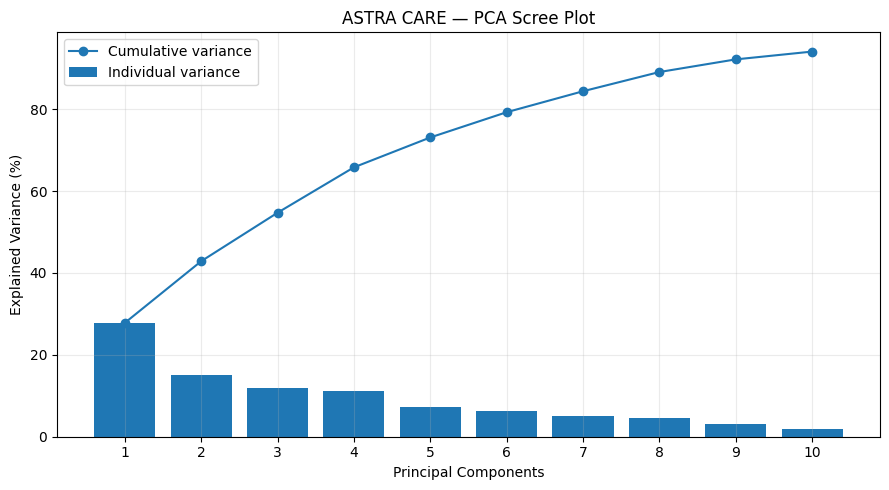

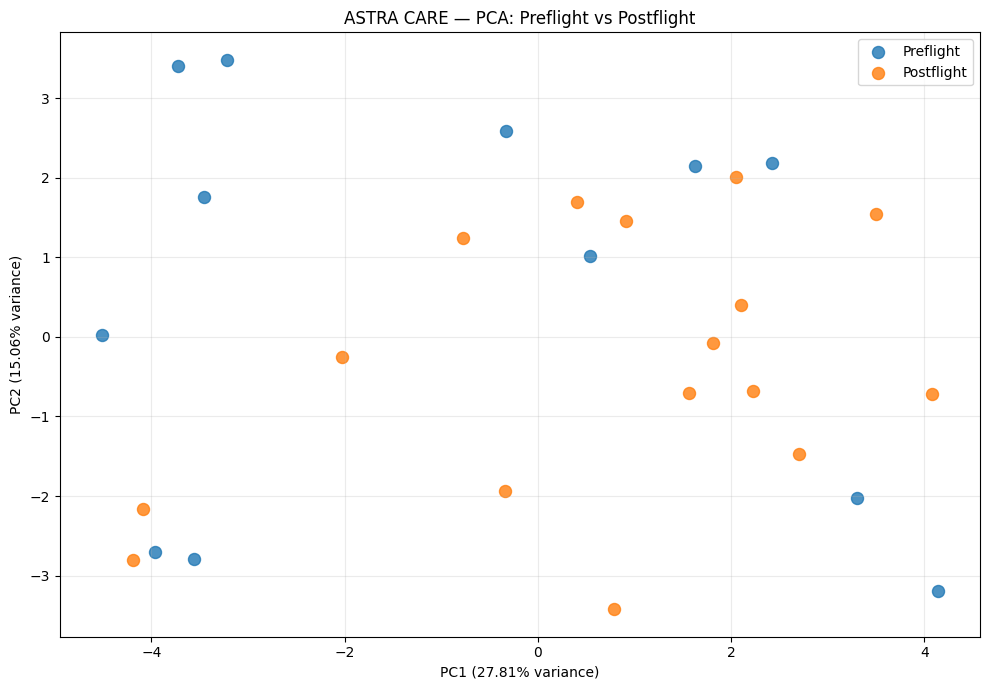


TOP 10 BIOMARKER LOADINGS — PC1


,Absolute_Loading
Biomarker,
SAP,0.327739
Fetuin A36,0.313731
PF4,0.302631
a-2 Macroglobulin,0.301526
L-Selectin,0.284705
Haptoglobin,0.266109
ALBUMIN,0.256314
CRP,0.251826
AGP,0.220064



TOP 10 BIOMARKER LOADINGS — PC2


,Absolute_Loading
Biomarker,
AST,0.398544
ALT,0.331820
ALKALINE PHOSPHATASE,0.314027
GLOBULIN,0.296789
ALBUMIN/GLOBULIN RATIO,0.291878
AGP,0.226670
SODIUM,0.222120
CALCIUM,0.212212
CREATININE,0.201962



PCA VALIDATION
Observations: 28
Components calculated: 10
PC1 variance: 27.81 %
PC2 variance: 15.06 %
PC1 + PC2 cumulative variance: 42.86 %

PCA OUTPUT FILES:
- pca_explained_variance.csv
- pca_loadings.csv
- pca_phase_scatter.png
- pca_scree_plot.png

PCA MODEL:
- pca_model.joblib

ASTRA CARE PCA COMPLETED SUCCESSFULLY


In [18]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

# ============================================================
# ASTRA CARE — PRINCIPAL COMPONENT ANALYSIS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"

PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")
MODEL_PATH = os.path.join(BASE_PATH, "models")

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

print("=" * 65)
print("ASTRA CARE — PRINCIPAL COMPONENT ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD PREPROCESSED DATA
# ------------------------------------------------------------

data = pd.read_csv(
    os.path.join(
        PROCESSED_PATH,
        "preprocessed_dataset.csv"
    )
)

metadata_columns = [
    "ID",
    "Timepoint",
    "Phase",
    "Timepoint_Order"
]

feature_columns = [
    col for col in data.columns
    if col not in metadata_columns
]

X = data[feature_columns].astype(float)

if X.isna().sum().sum() != 0:
    raise ValueError("Missing values detected in PCA input.")

if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Non-finite values detected in PCA input.")

print("\nInput dimensions:", X.shape)
print("Participants:", data["ID"].nunique())
print("Biomarkers:", len(feature_columns))

# ------------------------------------------------------------
# 2. FIT PCA
# ------------------------------------------------------------

pca = PCA(
    n_components=min(10, X.shape[0], X.shape[1]),
    random_state=42
)

principal_components = pca.fit_transform(X)

print("\nPCA fitting completed.")

# ------------------------------------------------------------
# 3. EXPLAINED VARIANCE
# ------------------------------------------------------------

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_report = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained_Variance_Percentage":
        explained_variance * 100,
    "Cumulative_Variance_Percentage":
        cumulative_variance * 100
})

variance_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "pca_explained_variance.csv"
    ),
    index=False
)

print("\nEXPLAINED VARIANCE REPORT")
display(variance_report)

print(
    "\nVariance explained by PC1 + PC2:",
    round(float(cumulative_variance[1] * 100), 2),
    "%"
)

# ------------------------------------------------------------
# 4. SAVE PCA COORDINATES
# ------------------------------------------------------------

pca_coordinates = data[metadata_columns].copy()

for i in range(principal_components.shape[1]):
    pca_coordinates[f"PC{i+1}"] = principal_components[:, i]

pca_coordinates.to_csv(
    os.path.join(
        PROCESSED_PATH,
        "pca_coordinates.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 5. SCREE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

components = np.arange(1, len(explained_variance) + 1)

plt.bar(
    components,
    explained_variance * 100,
    label="Individual variance"
)

plt.plot(
    components,
    cumulative_variance * 100,
    marker="o",
    label="Cumulative variance"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("ASTRA CARE — PCA Scree Plot")
plt.xticks(components)
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "pca_scree_plot.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 6. PC1 VS PC2 SCATTER PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for phase in ["Preflight", "Postflight"]:

    subset = pca_coordinates[
        pca_coordinates["Phase"] == phase
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=phase,
        s=75,
        alpha=0.8
    )

plt.xlabel(
    f"PC1 ({explained_variance[0] * 100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance[1] * 100:.2f}% variance)"
)

plt.title("ASTRA CARE — PCA: Preflight vs Postflight")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "pca_phase_scatter.png"),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 7. PCA LOADINGS
# ------------------------------------------------------------

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_columns,
    columns=[
        f"PC{i+1}" for i in range(pca.n_components_)
    ]
)

loadings.index.name = "Biomarker"

loadings.to_csv(
    os.path.join(OUTPUT_PATH, "pca_loadings.csv")
)

print("\nTOP 10 BIOMARKER LOADINGS — PC1")

display(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Absolute_Loading")
)

print("\nTOP 10 BIOMARKER LOADINGS — PC2")

display(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Absolute_Loading")
)

# ------------------------------------------------------------
# 8. SAVE PCA MODEL
# ------------------------------------------------------------

joblib.dump(
    pca,
    os.path.join(MODEL_PATH, "pca_model.joblib")
)

# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

assert principal_components.shape[0] == 28
assert principal_components.shape[1] >= 2

assert np.isfinite(principal_components).all()

print("\n" + "=" * 65)
print("PCA VALIDATION")
print("=" * 65)

print("Observations:", principal_components.shape[0])
print("Components calculated:", principal_components.shape[1])

print(
    "PC1 variance:",
    round(float(explained_variance[0] * 100), 2),
    "%"
)

print(
    "PC2 variance:",
    round(float(explained_variance[1] * 100), 2),
    "%"
)

print(
    "PC1 + PC2 cumulative variance:",
    round(float(cumulative_variance[1] * 100), 2),
    "%"
)

print("\nPCA OUTPUT FILES:")
for filename in sorted(os.listdir(OUTPUT_PATH)):
    if filename.startswith("pca_"):
        print("-", filename)

print("\nPCA MODEL:")
print("- pca_model.joblib")

print("\nASTRA CARE PCA COMPLETED SUCCESSFULLY")


ASTRA CARE — CLUSTERING ANALYSIS

Input shape: (28, 28)
K=2 | Silhouette=0.2141 | Inertia=596.6325
K=3 | Silhouette=0.1428 | Inertia=515.5490
K=4 | Silhouette=0.1626 | Inertia=449.0562
Agglomerative K=2 | Silhouette=0.2141
Agglomerative K=3 | Silhouette=0.1479
Agglomerative K=4 | Silhouette=0.1602

CLUSTERING COMPARISON


,Algorithm,Clusters,Silhouette_Score,Inertia
0,KMeans,2,0.214081,596.632499
1,Agglomerative,2,0.214081,NaN
2,KMeans,4,0.162602,449.056170
3,Agglomerative,4,0.160200,NaN
4,Agglomerative,3,0.147940,NaN
5,KMeans,3,0.142782,515.548961



Best exploratory configuration:
Algorithm: KMeans
Clusters: 2
Silhouette score: 0.2141

CLUSTER COUNTS


,Observations
Cluster,
0,9
1,19



CLUSTER BY PHASE


Phase,Postflight,Preflight
Cluster,,
0,3,6
1,13,6



CLUSTER BY PARTICIPANT


ID,C001,C002,C003,C004
Cluster,,,,
0,5,2,1,1
1,2,5,6,6


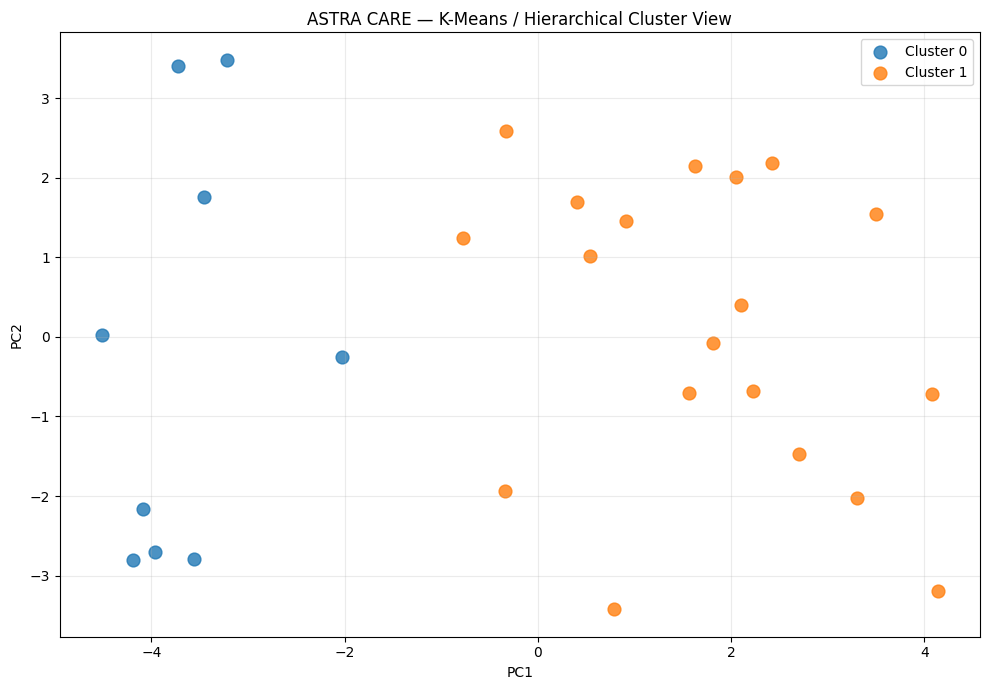

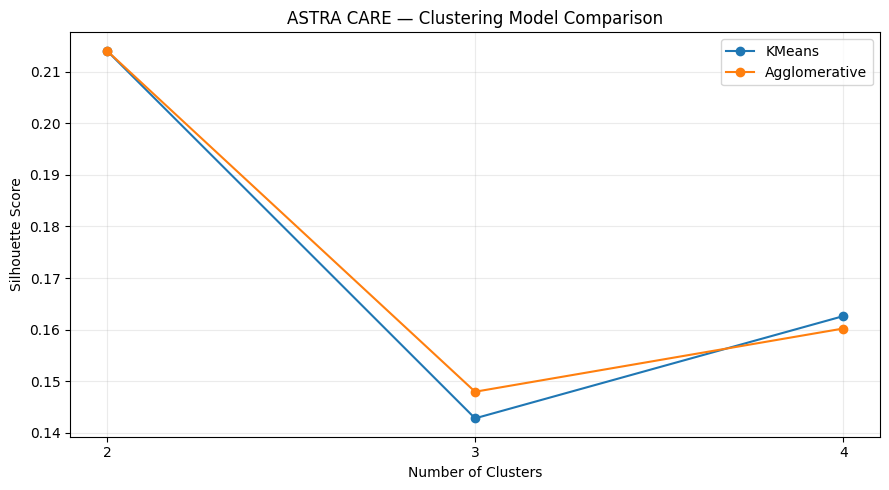


CLUSTERING VALIDATION
Observations: 28
Participants: 4
Selected algorithm: KMeans
Selected cluster count: 2
Cluster labels: [np.int32(0), np.int32(1)]

GENERATED FILES:
- cluster_participant_composition.csv
- cluster_phase_composition.csv
- clustering_comparison.csv
- clustering_pca_visualization.png
- clustering_silhouette_comparison.png

ASTRA CARE CLUSTERING COMPLETED


In [19]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# ============================================================
# ASTRA CARE — CLUSTERING ANALYSIS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"

PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")
MODEL_PATH = os.path.join(BASE_PATH, "models")

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

print("=" * 65)
print("ASTRA CARE — CLUSTERING ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD PREPROCESSED DATA
# ------------------------------------------------------------

data = pd.read_csv(
    os.path.join(PROCESSED_PATH, "preprocessed_dataset.csv")
)

metadata_columns = [
    "ID",
    "Timepoint",
    "Phase",
    "Timepoint_Order"
]

feature_columns = [
    col for col in data.columns
    if col not in metadata_columns
]

X = data[feature_columns].astype(float)

if X.isna().sum().sum() != 0:
    raise ValueError("Missing values detected.")

if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Non-finite values detected.")

print("\nInput shape:", X.shape)

# ------------------------------------------------------------
# 2. K-MEANS: TEST DIFFERENT CLUSTER COUNTS
# ------------------------------------------------------------

kmeans_results = []
kmeans_models = {}

for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    kmeans_models[k] = model

    kmeans_results.append({
        "Algorithm": "KMeans",
        "Clusters": k,
        "Silhouette_Score": score,
        "Inertia": model.inertia_
    })

    print(
        f"K={k} | "
        f"Silhouette={score:.4f} | "
        f"Inertia={model.inertia_:.4f}"
    )

# ------------------------------------------------------------
# 3. AGGLOMERATIVE CLUSTERING
# ------------------------------------------------------------

hierarchical_results = []
hierarchical_models = {}

for k in [2, 3, 4]:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    hierarchical_models[k] = model

    hierarchical_results.append({
        "Algorithm": "Agglomerative",
        "Clusters": k,
        "Silhouette_Score": score,
        "Inertia": np.nan
    })

    print(
        f"Agglomerative K={k} | "
        f"Silhouette={score:.4f}"
    )

# ------------------------------------------------------------
# 4. COMPARE CLUSTERING RESULTS
# ------------------------------------------------------------

results = pd.DataFrame(
    kmeans_results + hierarchical_results
)

results.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "clustering_comparison.csv"
    ),
    index=False
)

print("\nCLUSTERING COMPARISON")
display(
    results.sort_values(
        "Silhouette_Score",
        ascending=False
    ).reset_index(drop=True)
)

# Select the highest silhouette score for an exploratory
# partition. This is NOT a validated biological optimum.
best_row = results.loc[
    results["Silhouette_Score"].idxmax()
]

best_algorithm = best_row["Algorithm"]
best_k = int(best_row["Clusters"])

print("\nBest exploratory configuration:")
print("Algorithm:", best_algorithm)
print("Clusters:", best_k)
print(
    "Silhouette score:",
    round(float(best_row["Silhouette_Score"]), 4)
)

# ------------------------------------------------------------
# 5. GENERATE SELECTED CLUSTER LABELS
# ------------------------------------------------------------

if best_algorithm == "KMeans":
    selected_model = kmeans_models[best_k]
else:
    selected_model = hierarchical_models[best_k]

cluster_labels = selected_model.fit_predict(X)

clustered_data = data[metadata_columns].copy()

clustered_data["Cluster"] = cluster_labels

clustered_data.to_csv(
    os.path.join(
        PROCESSED_PATH,
        "cluster_assignments.csv"
    ),
    index=False
)

# Save KMeans model only when KMeans is selected.
if best_algorithm == "KMeans":
    joblib.dump(
        selected_model,
        os.path.join(
            MODEL_PATH,
            "kmeans_model.joblib"
        )
    )

# ------------------------------------------------------------
# 6. CLUSTER COMPOSITION
# ------------------------------------------------------------

print("\nCLUSTER COUNTS")

display(
    clustered_data["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Observations")
)

print("\nCLUSTER BY PHASE")

phase_table = pd.crosstab(
    clustered_data["Cluster"],
    clustered_data["Phase"]
)

display(phase_table)

phase_table.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "cluster_phase_composition.csv"
    )
)

print("\nCLUSTER BY PARTICIPANT")

participant_table = pd.crosstab(
    clustered_data["Cluster"],
    clustered_data["ID"]
)

display(participant_table)

participant_table.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "cluster_participant_composition.csv"
    )
)

# ------------------------------------------------------------
# 7. VISUALIZE CLUSTERS ON PCA SPACE
# ------------------------------------------------------------

pca_coordinates = pd.read_csv(
    os.path.join(
        PROCESSED_PATH,
        "pca_coordinates.csv"
    )
)

plot_data = pca_coordinates.copy()
plot_data["Cluster"] = cluster_labels

plt.figure(figsize=(10, 7))

for cluster in sorted(plot_data["Cluster"].unique()):

    subset = plot_data[
        plot_data["Cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=85,
        alpha=0.8,
        label=f"Cluster {cluster}"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("ASTRA CARE — K-Means / Hierarchical Cluster View")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_PATH,
        "clustering_pca_visualization.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 8. SILHOUETTE COMPARISON PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for algorithm in results["Algorithm"].unique():

    subset = results[
        results["Algorithm"] == algorithm
    ]

    plt.plot(
        subset["Clusters"],
        subset["Silhouette_Score"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("ASTRA CARE — Clustering Model Comparison")
plt.xticks([2, 3, 4])
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_PATH,
        "clustering_silhouette_comparison.png"
    ),
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 9. FINAL VALIDATION
# ------------------------------------------------------------

assert len(clustered_data) == 28
assert clustered_data["Cluster"].notna().all()
assert clustered_data["ID"].nunique() == 4

print("\n" + "=" * 65)
print("CLUSTERING VALIDATION")
print("=" * 65)

print("Observations:", len(clustered_data))
print("Participants:", clustered_data["ID"].nunique())
print("Selected algorithm:", best_algorithm)
print("Selected cluster count:", best_k)
print("Cluster labels:", sorted(clustered_data["Cluster"].unique()))

print("\nGENERATED FILES:")

for filename in sorted(os.listdir(OUTPUT_PATH)):
    if filename.startswith("cluster"):
        print("-", filename)

print("\nASTRA CARE CLUSTERING COMPLETED")


In [20]:

import os
import numpy as np
import pandas as pd
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ============================================================
# ASTRA CARE — PARTICIPANT-LEVEL CLASSIFICATION
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"

PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")
MODEL_PATH = os.path.join(BASE_PATH, "models")

os.makedirs(OUTPUT_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

print("=" * 65)
print("ASTRA CARE — SUPERVISED CLASSIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD ORIGINAL INTEGRATED DATA
# ------------------------------------------------------------

data = pd.read_csv(
    os.path.join(PROCESSED_PATH, "integrated_wide.csv")
)

metadata_columns = [
    "ID",
    "Timepoint",
    "Phase",
    "Timepoint_Order"
]

for column in metadata_columns:
    if column not in data.columns:
        raise ValueError(f"Missing metadata column: {column}")

# Exclude race-specific eGFR estimates pending scientific review.
excluded_features = [
    "eGFR AFRICAN AMERICAN",
    "eGFR NON-AFR. AMERICAN"
]

feature_columns = [
    col for col in data.columns
    if col not in metadata_columns
    and col not in excluded_features
]

X = data[feature_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Target: Preflight = 0, Postflight = 1
phase = data["Phase"].astype(str).str.strip()

valid_phases = {"Preflight", "Postflight"}

if not set(phase.unique()).issubset(valid_phases):
    raise ValueError(
        f"Unexpected phase labels: {phase.unique()}"
    )

y = phase.map({
    "Preflight": 0,
    "Postflight": 1
}).astype(int)

groups = data["ID"].astype(str)

if X.shape[0] != 28:
    raise ValueError("Expected 28 observations.")

if X.shape[1] == 0:
    raise ValueError("No usable features found.")

if (X.min(skipna=True) < 0).any():
    raise ValueError(
        "Negative biomarker values detected. "
        "Review before applying log1p."
    )

print("\nDataset shape:", X.shape)
print("Participants:", groups.nunique())
print("Biomarkers used:", len(feature_columns))

print("\nPhase distribution:")
print(phase.value_counts())

print("\nPhase distribution by participant:")
display(pd.crosstab(groups, phase))

# ------------------------------------------------------------
# 2. DEFINE LEAKAGE-SAFE PREPROCESSING
# ------------------------------------------------------------

def make_pipeline(classifier):

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log_transform", FunctionTransformer(
            np.log1p,
            validate=False
        )),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

models = {
    "Majority Baseline": make_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),

    "Logistic Regression": make_pipeline(
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        )
    ),

    "SVM": make_pipeline(
        SVC(
            kernel="rbf",
            C=1.0,
            class_weight="balanced"
        )
    ),

    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(
            max_depth=3,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        )
    )
}

# ------------------------------------------------------------
# 3. LEAVE-ONE-PARTICIPANT-OUT VALIDATION
# ------------------------------------------------------------

logo = LeaveOneGroupOut()

all_predictions = []
summary_results = []

for model_name, pipeline in models.items():

    print("\nEvaluating:", model_name)

    predictions = np.full(len(y), -1, dtype=int)

    for train_index, test_index in logo.split(
        X, y, groups
    ):

        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]

        y_train = y.iloc[train_index]

        # Every training fold must contain both phases.
        if y_train.nunique() != 2:
            raise ValueError(
                "Training fold does not contain both classes."
            )

        fold_model = clone(pipeline)

        fold_model.fit(X_train, y_train)

        predictions[test_index] = fold_model.predict(
            X_test
        )

    if (predictions == -1).any():
        raise ValueError("Some observations were not predicted.")

    # Pooled out-of-participant predictions
    accuracy = accuracy_score(y, predictions)

    balanced_accuracy = balanced_accuracy_score(
        y, predictions
    )

    precision = precision_score(
        y, predictions, zero_division=0
    )

    recall = recall_score(
        y, predictions, zero_division=0
    )

    f1 = f1_score(
        y, predictions, zero_division=0
    )

    auc = roc_auc_score(y, predictions)

    summary_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "ROC_AUC_Hard_Predictions": auc
    })

    for index in range(len(y)):

        all_predictions.append({
            "Model": model_name,
            "ID": groups.iloc[index],
            "Timepoint": data["Timepoint"].iloc[index],
            "Actual_Phase": phase.iloc[index],
            "Actual_Label": int(y.iloc[index]),
            "Predicted_Label": int(predictions[index]),
            "Correct": bool(
                y.iloc[index] == predictions[index]
            )
        })

# ------------------------------------------------------------
# 4. MODEL COMPARISON
# ------------------------------------------------------------

summary = pd.DataFrame(summary_results)

summary = summary.sort_values(
    "Balanced_Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE — POOLED HELD-OUT PREDICTIONS")
display(summary)

summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "classification_model_comparison.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 5. SAVE INDIVIDUAL PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame(all_predictions)

prediction_df.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "classification_predictions.csv"
    ),
    index=False
)

print("\nINDIVIDUAL PARTICIPANT PREDICTIONS")
display(
    prediction_df[
        prediction_df["Model"] == "Logistic Regression"
    ]
)

# ------------------------------------------------------------
# 6. PARTICIPANT-LEVEL PERFORMANCE
# ------------------------------------------------------------

print("\nLOGISTIC REGRESSION — PARTICIPANT-LEVEL RESULTS")

logistic_predictions = prediction_df[
    prediction_df["Model"] == "Logistic Regression"
].copy()

participant_results = []

for participant in sorted(groups.unique()):

    subset = logistic_predictions[
        logistic_predictions["ID"] == participant
    ]

    participant_results.append({
        "Participant": participant,
        "Observations": len(subset),
        "Accuracy": accuracy_score(
            subset["Actual_Label"],
            subset["Predicted_Label"]
        ),
        "Correct_Predictions": int(
            subset["Correct"].sum()
        )
    })

participant_results = pd.DataFrame(
    participant_results
)

display(participant_results)

participant_results.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "classification_participant_performance.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

print("\nLOGISTIC REGRESSION — CONFUSION MATRIX")

cm = confusion_matrix(
    logistic_predictions["Actual_Label"],
    logistic_predictions["Predicted_Label"],
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Preflight", "Actual Postflight"],
    columns=["Predicted Preflight", "Predicted Postflight"]
)

display(cm_df)

cm_df.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "classification_confusion_matrix.csv"
    )
)

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        logistic_predictions["Actual_Label"],
        logistic_predictions["Predicted_Label"],
        labels=[0, 1],
        target_names=["Preflight", "Postflight"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 8. FINAL VALIDATION
# ------------------------------------------------------------

assert len(prediction_df) == len(models) * 28
assert participant_results.shape[0] == 4
assert not prediction_df["Predicted_Label"].isna().any()

print("\n" + "=" * 65)
print("CLASSIFICATION VALIDATION")
print("=" * 65)

print("Observations:", len(X))
print("Participants:", groups.nunique())
print("Biomarkers:", len(feature_columns))
print("Validation: Leave-One-Participant-Out")
print("Models evaluated:", len(models))
print("Predictions per model:", len(y))

print("\nGENERATED OUTPUTS:")

for filename in sorted(os.listdir(OUTPUT_PATH)):
    if filename.startswith("classification"):
        print("-", filename)

print("\nASTRA CARE CLASSIFICATION COMPLETED")


ASTRA CARE — SUPERVISED CLASSIFICATION

Dataset shape: (28, 26)
Participants: 4
Biomarkers used: 26

Phase distribution:
Phase
Postflight    16
Preflight     12
Name: count, dtype: int64

Phase distribution by participant:


Phase,Postflight,Preflight
ID,,
C001,4,3
C002,4,3
C003,4,3
C004,4,3



Evaluating: Majority Baseline

Evaluating: Logistic Regression

Evaluating: Random Forest

Evaluating: SVM

Evaluating: Decision Tree

MODEL PERFORMANCE — POOLED HELD-OUT PREDICTIONS


,Model,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score,ROC_AUC_Hard_Predictions
0,SVM,0.678571,0.635417,0.652174,0.9375,0.769231,0.635417
1,Random Forest,0.642857,0.625000,0.666667,0.7500,0.705882,0.625000
2,Logistic Regression,0.642857,0.625000,0.666667,0.7500,0.705882,0.625000
3,Decision Tree,0.642857,0.614583,0.650000,0.8125,0.722222,0.614583
4,Majority Baseline,0.571429,0.500000,0.571429,1.0000,0.727273,0.500000



INDIVIDUAL PARTICIPANT PREDICTIONS


,Model,ID,Timepoint,Actual_Phase,Actual_Label,Predicted_Label,Correct
28,Logistic Regression,C001,L-92,Preflight,0,0,True
29,Logistic Regression,C001,L-44,Preflight,0,0,True
30,Logistic Regression,C001,L-3,Preflight,0,0,True
31,Logistic Regression,C001,R+1,Postflight,1,1,True
32,Logistic Regression,C001,R+45,Postflight,1,0,False
33,Logistic Regression,C001,R+82,Postflight,1,1,True
34,Logistic Regression,C001,R+194,Postflight,1,1,True
35,Logistic Regression,C002,L-92,Preflight,0,1,False
36,Logistic Regression,C002,L-44,Preflight,0,1,False
37,Logistic Regression,C002,L-3,Preflight,0,1,False



LOGISTIC REGRESSION — PARTICIPANT-LEVEL RESULTS


,Participant,Observations,Accuracy,Correct_Predictions
0,C001,7,0.857143,6
1,C002,7,0.571429,4
2,C003,7,0.714286,5
3,C004,7,0.428571,3



LOGISTIC REGRESSION — CONFUSION MATRIX


,Predicted Preflight,Predicted Postflight
Actual Preflight,6,6
Actual Postflight,4,12



CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Preflight       0.60      0.50      0.55        12
  Postflight       0.67      0.75      0.71        16

    accuracy                           0.64        28
   macro avg       0.63      0.62      0.63        28
weighted avg       0.64      0.64      0.64        28


CLASSIFICATION VALIDATION
Observations: 28
Participants: 4
Biomarkers: 26
Validation: Leave-One-Participant-Out
Models evaluated: 5
Predictions per model: 28

GENERATED OUTPUTS:
- classification_confusion_matrix.csv
- classification_model_comparison.csv
- classification_participant_performance.csv
- classification_predictions.csv

ASTRA CARE CLASSIFICATION COMPLETED


In [21]:

import os
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")

predictions = pd.read_csv(
    os.path.join(
        OUTPUT_PATH,
        "classification_predictions.csv"
    )
)

results = []

for model_name in predictions["Model"].unique():

    model_data = predictions[
        predictions["Model"] == model_name
    ]

    for participant in sorted(model_data["ID"].unique()):

        subset = model_data[
            model_data["ID"] == participant
        ]

        results.append({
            "Model": model_name,
            "Participant": participant,
            "Observations": len(subset),
            "Accuracy": accuracy_score(
                subset["Actual_Label"],
                subset["Predicted_Label"]
            ),
            "Balanced_Accuracy": balanced_accuracy_score(
                subset["Actual_Label"],
                subset["Predicted_Label"]
            )
        })

stability = pd.DataFrame(results)

print("=" * 65)
print("ASTRA CARE — PARTICIPANT-LEVEL MODEL STABILITY")
print("=" * 65)

display(
    stability.pivot(
        index="Model",
        columns="Participant",
        values="Accuracy"
    ).round(3)
)

print("\nAVERAGE PARTICIPANT-LEVEL PERFORMANCE")

average_results = (
    stability.groupby("Model")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Mean_Balanced_Accuracy=("Balanced_Accuracy", "mean"),
        Minimum_Accuracy=("Accuracy", "min"),
        Maximum_Accuracy=("Accuracy", "max")
    )
    .sort_values(
        "Mean_Balanced_Accuracy",
        ascending=False
    )
)

display(average_results.round(4))

stability.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "participant_model_stability.csv"
    ),
    index=False
)

average_results.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "participant_model_stability_summary.csv"
    )
)

print("\nSaved:")
print("- participant_model_stability.csv")
print("- participant_model_stability_summary.csv")

print("\nSTABILITY ANALYSIS COMPLETED")


ASTRA CARE — PARTICIPANT-LEVEL MODEL STABILITY


Participant,C001,C002,C003,C004
Model,,,,
Decision Tree,0.571,0.571,0.571,0.857
Logistic Regression,0.857,0.571,0.714,0.429
Majority Baseline,0.571,0.571,0.571,0.571
Random Forest,0.429,0.571,0.714,0.857
SVM,0.714,0.714,0.571,0.714



AVERAGE PARTICIPANT-LEVEL PERFORMANCE


,Mean_Accuracy,Mean_Balanced_Accuracy,Minimum_Accuracy,Maximum_Accuracy
Model,,,,
SVM,0.6786,0.6354,0.5714,0.7143
Random Forest,0.6429,0.6250,0.4286,0.8571
Logistic Regression,0.6429,0.6250,0.4286,0.8571
Decision Tree,0.6429,0.6146,0.5714,0.8571
Majority Baseline,0.5714,0.5000,0.5714,0.5714



Saved:
- participant_model_stability.csv
- participant_model_stability_summary.csv

STABILITY ANALYSIS COMPLETED


ASTRA CARE — EXPLAINABLE AI
Observations: 28
Participants: 4
Features: 26

Fold 1: Held-out participant = C001

Fold 2: Held-out participant = C002

Fold 3: Held-out participant = C003

Fold 4: Held-out participant = C004

TOP 15 BIOMARKERS — EXPLORATORY IMPORTANCE


,Biomarker,Mean_Importance,Between_Participant_SD,Mean_Permutation_SD
9,CARBON DIOXIDE,0.021875,0.043750,0.014321
25,a-2 Macroglobulin,0.018750,0.037500,0.015309
22,SAP,0.017188,0.034375,0.015547
23,SODIUM,0.015625,0.044634,0.032789
17,Haptoglobin,0.015104,0.030208,0.019894
5,AST,0.014063,0.028125,0.018422
7,BUN/CREATININE RATIO,0.012500,0.025000,0.015309
8,CALCIUM,0.012500,0.025000,0.015309
13,Fetuin A36,0.010937,0.021875,0.014905
18,L-Selectin,0.010937,0.021875,0.014905



TOP BIOMARKER IMPORTANCE BY PARTICIPANT


Participant,C001,C002,C003,C004
Biomarker,,,,
CARBON DIOXIDE,0.0,0.00000,0.0,0.087500
a-2 Macroglobulin,0.0,0.00000,0.0,0.075000
SAP,0.0,0.00000,0.0,0.068750
SODIUM,0.0,0.08125,0.0,-0.018750
Haptoglobin,0.0,0.00000,0.0,0.060417
AST,0.0,0.00000,0.0,0.056250
BUN/CREATININE RATIO,0.0,0.00000,0.0,0.050000
CALCIUM,0.0,0.00000,0.0,0.050000
Fetuin A36,0.0,0.00000,0.0,0.043750


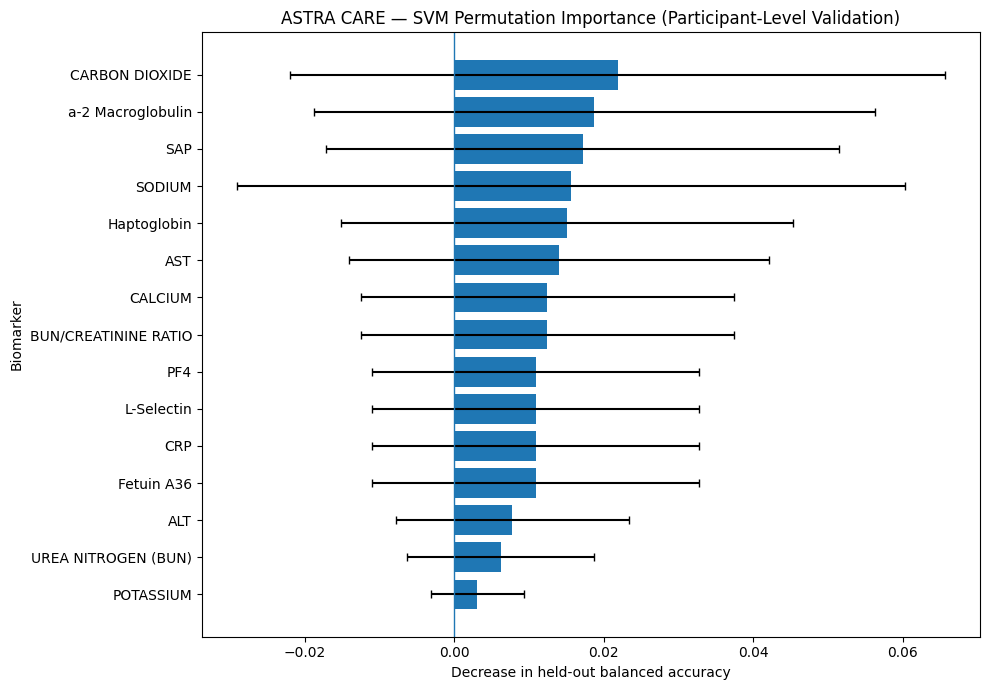


XAI VALIDATION
Participants evaluated: 4
Biomarkers evaluated: 26
Permutation repeats per participant: 20

GENERATED FILES:
- xai_participant_permutation_importance.csv
- xai_biomarker_importance_summary.csv
- xai_participant_importance_matrix.csv
- xai_biomarker_importance.png

ASTRA CARE XAI COMPLETED


In [22]:

import os
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.inspection import permutation_importance

# ============================================================
# ASTRA CARE — EXPLAINABLE AI
# SVM + LEAVE-ONE-PARTICIPANT-OUT PERMUTATION IMPORTANCE
# ============================================================

BASE_PATH = "/content/drive/MyDrive/ASTRA_CARE_AIML"

PROCESSED_PATH = os.path.join(BASE_PATH, "data", "processed")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("=" * 65)
print("ASTRA CARE — EXPLAINABLE AI")
print("=" * 65)

# 1. LOAD DATA

data = pd.read_csv(
    os.path.join(PROCESSED_PATH, "integrated_wide.csv")
)

metadata_columns = [
    "ID", "Timepoint", "Phase", "Timepoint_Order"
]

excluded_features = [
    "eGFR AFRICAN AMERICAN",
    "eGFR NON-AFR. AMERICAN"
]

feature_columns = [
    col for col in data.columns
    if col not in metadata_columns
    and col not in excluded_features
]

X = data[feature_columns].apply(
    pd.to_numeric, errors="coerce"
)

phase = data["Phase"].astype(str).str.strip()

y = phase.map({
    "Preflight": 0,
    "Postflight": 1
}).astype(int)

groups = data["ID"].astype(str)

print("Observations:", len(X))
print("Participants:", groups.nunique())
print("Features:", len(feature_columns))

# 2. DEFINE SVM PIPELINE

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(
        np.log1p, validate=False
    )),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced"
    ))
])

# 3. PARTICIPANT-LEVEL PERMUTATION IMPORTANCE

logo = LeaveOneGroupOut()

importance_records = []

fold_number = 0

for train_index, test_index in logo.split(X, y, groups):

    fold_number += 1

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    held_out_participant = groups.iloc[test_index].iloc[0]

    print(
        f"\nFold {fold_number}: "
        f"Held-out participant = {held_out_participant}"
    )

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log_transform", FunctionTransformer(
            np.log1p, validate=False
        )),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            class_weight="balanced"
        ))
    ])

    model.fit(X_train, y_train)

    importance = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="balanced_accuracy",
        n_repeats=20,
        random_state=42
    )

    for i, feature in enumerate(feature_columns):

        importance_records.append({
            "Participant": held_out_participant,
            "Biomarker": feature,
            "Importance_Mean": importance.importances_mean[i],
            "Importance_Std": importance.importances_std[i]
        })

# 4. SAVE PARTICIPANT-LEVEL IMPORTANCE

importance_df = pd.DataFrame(importance_records)

importance_df.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "xai_participant_permutation_importance.csv"
    ),
    index=False
)

# 5. AGGREGATE ACROSS PARTICIPANTS

summary = (
    importance_df
    .groupby("Biomarker")
    .agg(
        Mean_Importance=("Importance_Mean", "mean"),
        Between_Participant_SD=("Importance_Mean", "std"),
        Mean_Permutation_SD=("Importance_Std", "mean")
    )
    .reset_index()
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
)

summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "xai_biomarker_importance_summary.csv"
    ),
    index=False
)

print("\nTOP 15 BIOMARKERS — EXPLORATORY IMPORTANCE")

display(summary.head(15))

# 6. PARTICIPANT-LEVEL COMPARISON

participant_summary = importance_df.pivot(
    index="Biomarker",
    columns="Participant",
    values="Importance_Mean"
)

print("\nTOP BIOMARKER IMPORTANCE BY PARTICIPANT")

display(
    participant_summary.loc[
        summary.head(10)["Biomarker"]
    ]
)

participant_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "xai_participant_importance_matrix.csv"
    )
)

# 7. VISUALIZATION

import matplotlib.pyplot as plt

top_features = summary.head(15).sort_values(
    "Mean_Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Biomarker"],
    top_features["Mean_Importance"],
    xerr=top_features["Between_Participant_SD"],
    capsize=3
)

plt.axvline(0, linewidth=1)
plt.xlabel("Decrease in held-out balanced accuracy")
plt.ylabel("Biomarker")
plt.title(
    "ASTRA CARE — SVM Permutation Importance "
    "(Participant-Level Validation)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_PATH,
        "xai_biomarker_importance.png"
    ),
    dpi=300
)

plt.show()

# 8. VALIDATION

assert importance_df["Participant"].nunique() == 4
assert len(importance_df) == 4 * len(feature_columns)
assert summary["Biomarker"].nunique() == len(feature_columns)

print("\n" + "=" * 65)
print("XAI VALIDATION")
print("=" * 65)

print("Participants evaluated:", importance_df["Participant"].nunique())
print("Biomarkers evaluated:", len(feature_columns))
print("Permutation repeats per participant:", 20)

print("\nGENERATED FILES:")
print("- xai_participant_permutation_importance.csv")
print("- xai_biomarker_importance_summary.csv")
print("- xai_participant_importance_matrix.csv")
print("- xai_biomarker_importance.png")

print("\nASTRA CARE XAI COMPLETED")


In [26]:

import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/processed/integrated_wide.csv"
df = pd.read_csv(path)

print("ALL DATASET COLUMNS:")
for col in df.columns:
    print(repr(col))

# Exclude metadata and the two eGFR columns, case-insensitively
excluded = {
    "id", "timepoint", "phase",
    "egfr african american",
    "egfr non-afr. american"
}

features = [
    c for c in df.columns
    if c.strip().lower() not in excluded
]

X_check = df[features].apply(pd.to_numeric, errors="coerce")

print("\nFEATURE COUNT:", len(features))
print("\nNON-NUMERIC / MISSING VALUE COUNTS:")
print(X_check.isna().sum()[X_check.isna().sum() > 0])

print("\nFEATURES WITH VALUES <= -1:")
for col in X_check.columns:
    values = X_check[col].dropna()
    if (values <= -1).any():
        print(col, "Minimum:", values.min())

print("\nFINAL MATRIX SHAPE:", X_check.shape)
print("TOTAL MISSING VALUES:", X_check.isna().sum().sum())


ALL DATASET COLUMNS:
'ID'
'Timepoint'
'Phase'
'AGP'
'ALBUMIN'
'ALBUMIN/GLOBULIN RATIO'
'ALKALINE PHOSPHATASE'
'ALT'
'AST'
'BILIRUBIN; TOTAL'
'BUN/CREATININE RATIO'
'CALCIUM'
'CARBON DIOXIDE'
'CHLORIDE'
'CREATININE'
'CRP'
'Fetuin A36'
'Fibrinogen'
'GLOBULIN'
'GLUCOSE'
'Haptoglobin'
'L-Selectin'
'PF4'
'POTASSIUM'
'PROTEIN; TOTAL'
'SAP'
'SODIUM'
'UREA NITROGEN (BUN)'
'a-2 Macroglobulin'
'eGFR AFRICAN AMERICAN'
'eGFR NON-AFR. AMERICAN'
'Timepoint_Order'

FEATURE COUNT: 27

NON-NUMERIC / MISSING VALUE COUNTS:
BILIRUBIN; TOTAL    1
dtype: int64

FEATURES WITH VALUES <= -1:
Timepoint_Order Minimum: -92

FINAL MATRIX SHAPE: (28, 27)
TOTAL MISSING VALUES: 1


In [27]:

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

# Load original integrated dataset
path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/processed/integrated_wide.csv"
df = pd.read_csv(path)

# Exclude all metadata and race-specific eGFR features
excluded = [
    "ID",
    "Timepoint",
    "Timepoint_Order",
    "Phase",
    "eGFR AFRICAN AMERICAN",
    "eGFR NON-AFR. AMERICAN"
]

features = [c for c in df.columns if c not in excluded]

X = df[features].apply(pd.to_numeric, errors="coerce")
y = df["Phase"].map({"Preflight": 0, "Postflight": 1})
groups = df["ID"]

print("FEATURE COUNT:", len(features))
print("MISSING VALUES:", X.isna().sum().sum())
print("MINIMUM BIOMARKER VALUE:", X.min().min())

assert len(features) == 26, "Expected exactly 26 biomarkers."
assert not (X.min() <= -1).any(), "A biomarker contains a value <= -1."
assert y.notna().all(), "Missing phase labels."

# Same SVM configuration used in the XAI stage
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1,
        class_weight="balanced"
    ))
])

# Leave one participant out
logo = LeaveOneGroupOut()

print("\nASTRA CARE — CORRECTED XAI FOLD DIAGNOSTICS")

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups), start=1
):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    participant = groups.iloc[test_idx].iloc[0]

    print("\nFold:", fold)
    print("Held-out participant:", participant)

    print("Actual class counts:")
    print(y_test.value_counts().sort_index().to_dict())

    print("Predicted class counts:")
    print(pd.Series(predictions).value_counts().sort_index().to_dict())

    print(
        "Balanced accuracy:",
        round(balanced_accuracy_score(y_test, predictions), 4)
    )

    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))


FEATURE COUNT: 26
MISSING VALUES: 1
MINIMUM BIOMARKER VALUE: 0.2

ASTRA CARE — CORRECTED XAI FOLD DIAGNOSTICS

Fold: 1
Held-out participant: C001
Actual class counts:
{0: 3, 1: 4}
Predicted class counts:
{0: 1, 1: 6}
Balanced accuracy: 0.6667
Confusion matrix:
[[1 2]
 [0 4]]

Fold: 2
Held-out participant: C002
Actual class counts:
{0: 3, 1: 4}
Predicted class counts:
{0: 1, 1: 6}
Balanced accuracy: 0.6667
Confusion matrix:
[[1 2]
 [0 4]]

Fold: 3
Held-out participant: C003
Actual class counts:
{0: 3, 1: 4}
Predicted class counts:
{1: 7}
Balanced accuracy: 0.5
Confusion matrix:
[[0 3]
 [0 4]]

Fold: 4
Held-out participant: C004
Actual class counts:
{0: 3, 1: 4}
Predicted class counts:
{0: 3, 1: 4}
Balanced accuracy: 0.7083
Confusion matrix:
[[2 1]
 [1 3]]


In [28]:

from sklearn.inspection import permutation_importance
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.svm import SVC

import pandas as pd
import numpy as np

# Load original integrated dataset
path = "/content/drive/MyDrive/ASTRA_CARE_AIML/data/processed/integrated_wide.csv"
df = pd.read_csv(path)

# Exact corrected feature selection
excluded = [
    "ID", "Timepoint", "Timepoint_Order", "Phase",
    "eGFR AFRICAN AMERICAN",
    "eGFR NON-AFR. AMERICAN"
]

features = [c for c in df.columns if c not in excluded]

X = df[features].apply(pd.to_numeric, errors="coerce")
y = df["Phase"].map({"Preflight": 0, "Postflight": 1})
groups = df["ID"]

assert len(features) == 26

# Same SVM pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1,
        class_weight="balanced"
    ))
])

logo = LeaveOneGroupOut()

participant_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    participant = groups.iloc[test_idx].iloc[0]

    model.fit(X_train, y_train)

    result = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="balanced_accuracy",
        n_repeats=20,
        random_state=42
    )

    for i, feature in enumerate(features):
        participant_results.append({
            "Participant": participant,
            "Biomarker": feature,
            "Mean_Importance": result.importances_mean[i],
            "Permutation_SD": result.importances_std[i]
        })

    print("Completed fold:", fold, "| Participant:", participant)

# Save detailed results
participant_df = pd.DataFrame(participant_results)

participant_path = (
    "/content/drive/MyDrive/ASTRA_CARE_AIML/outputs/"
    "xai_corrected_participant_importance.csv"
)

participant_df.to_csv(participant_path, index=False)

# Aggregate across participants
summary = (
    participant_df.groupby("Biomarker")
    .agg(
        Mean_Importance=("Mean_Importance", "mean"),
        Between_Participant_SD=("Mean_Importance", "std"),
        Mean_Permutation_SD=("Permutation_SD", "mean")
    )
    .sort_values("Mean_Importance", ascending=False)
    .reset_index()
)

summary_path = (
    "/content/drive/MyDrive/ASTRA_CARE_AIML/outputs/"
    "xai_corrected_biomarker_summary.csv"
)

summary.to_csv(summary_path, index=False)

print("\nCORRECTED XAI — TOP 15 BIOMARKERS")
print(summary.head(15).to_string(index=False))

print("\nFILES SAVED:")
print(participant_path)
print(summary_path)


Completed fold: 1 | Participant: C001
Completed fold: 2 | Participant: C002
Completed fold: 3 | Participant: C003
Completed fold: 4 | Participant: C004

CORRECTED XAI — TOP 15 BIOMARKERS
           Biomarker  Mean_Importance  Between_Participant_SD  Mean_Permutation_SD
      CARBON DIOXIDE         0.021875                0.043750             0.014321
   a-2 Macroglobulin         0.018750                0.037500             0.015309
                 SAP         0.017188                0.034375             0.015547
              SODIUM         0.015625                0.044634             0.032789
         Haptoglobin         0.015104                0.030208             0.019894
                 AST         0.014063                0.028125             0.018422
BUN/CREATININE RATIO         0.012500                0.025000             0.015309
             CALCIUM         0.012500                0.025000             0.015309
          Fetuin A36         0.010937                0.021875     

In [29]:

from pathlib import Path
import pandas as pd
from datetime import datetime

# ASTRA CARE project directories
BASE = Path("/content/drive/MyDrive/ASTRA_CARE_AIML")
DATA = BASE / "data" / "processed"
OUTPUTS = BASE / "outputs"
MODELS = BASE / "models"

OUTPUTS.mkdir(parents=True, exist_ok=True)

# Important research files to verify
files_to_check = [
    DATA / "integrated_long.csv",
    DATA / "integrated_wide.csv",
    DATA / "imputed_dataset.csv",
    DATA / "log_transformed_dataset.csv",
    DATA / "preprocessed_dataset.csv",
    DATA / "pca_coordinates.csv",
    DATA / "cluster_assignments.csv",
    OUTPUTS / "pca_explained_variance.csv",
    OUTPUTS / "pca_loadings.csv",
    OUTPUTS / "clustering_comparison.csv",
    OUTPUTS / "classification_model_comparison.csv",
    OUTPUTS / "classification_predictions.csv",
    OUTPUTS / "participant_model_stability.csv",
    OUTPUTS / "participant_model_stability_summary.csv",
    OUTPUTS / "xai_corrected_participant_importance.csv",
    OUTPUTS / "xai_corrected_biomarker_summary.csv",
    MODELS / "median_imputer.joblib",
    MODELS / "standard_scaler.joblib",
    MODELS / "pca_model.joblib"
]

manifest = []

for file in files_to_check:
    exists = file.exists()

    row_count = None
    column_count = None

    if exists and file.suffix.lower() == ".csv":
        try:
            temp = pd.read_csv(file)
            row_count = len(temp)
            column_count = len(temp.columns)
        except Exception as e:
            print("Could not read:", file.name, "|", str(e))

    manifest.append({
        "File": str(file.relative_to(BASE)),
        "Exists": exists,
        "Rows": row_count,
        "Columns": column_count,
        "Size_KB": round(file.stat().st_size / 1024, 2)
                    if exists else None
    })

manifest_df = pd.DataFrame(manifest)

# Specific consistency checks
wide_path = DATA / "integrated_wide.csv"
xai_path = OUTPUTS / "xai_corrected_biomarker_summary.csv"
xai_participant_path = OUTPUTS / "xai_corrected_participant_importance.csv"

checks = {}

if wide_path.exists():
    wide = pd.read_csv(wide_path)
    checks["Integrated observations = 28"] = len(wide) == 28
    checks["Four participants present"] = (
        wide["ID"].nunique() == 4
    )
    checks["Seven timepoints present"] = (
        wide["Timepoint"].nunique() == 7
    )

if xai_path.exists():
    xai = pd.read_csv(xai_path)
    checks["XAI biomarkers = 26"] = len(xai) == 26

if xai_participant_path.exists():
    xai_detail = pd.read_csv(xai_participant_path)
    checks["XAI participant folds = 4"] = (
        xai_detail["Participant"].nunique() == 4
    )
    checks["XAI records = 104"] = len(xai_detail) == 104

# Save manifest
manifest_path = OUTPUTS / "research_validation_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

# Build audit report
report = []

report.append("ASTRA CARE — RESEARCH VALIDATION AUDIT")
report.append("=" * 55)
report.append("Audit date: " + datetime.now().strftime("%Y-%m-%d %H:%M"))
report.append("")

report.append("FILE VERIFICATION")
report.append("-" * 55)

for _, row in manifest_df.iterrows():
    status = "PRESENT" if row["Exists"] else "MISSING"
    report.append(f"{status}: {row['File']}")

report.append("")
report.append("DATA CONSISTENCY CHECKS")
report.append("-" * 55)

for name, passed in checks.items():
    report.append(f"{'PASS' if passed else 'FAIL'}: {name}")

report.append("")
report.append("SUMMARY")
report.append("-" * 55)
report.append(f"Files checked: {len(manifest_df)}")
report.append(f"Files present: {manifest_df['Exists'].sum()}")
report.append(f"Files missing: {(~manifest_df['Exists']).sum()}")
report.append(f"Consistency checks passed: {sum(checks.values())}")
report.append(f"Consistency checks failed: {len(checks) - sum(checks.values())}")

report.append("")
report.append("SCIENTIFIC LIMITATIONS")
report.append("-" * 55)
report.append("Only four independent participants were available.")
report.append("Repeated measurements are not independent participants.")
report.append("Classification and XAI findings are exploratory.")
report.append("No clinical diagnostic claims are supported.")
report.append("Race-specific eGFR features were excluded from classification.")

report_text = "\n".join(report)

audit_path = OUTPUTS / "research_validation_audit.txt"
audit_path.write_text(report_text, encoding="utf-8")

print(report_text)

print("\nFILES GENERATED:")
print(manifest_path)
print(audit_path)


ASTRA CARE — RESEARCH VALIDATION AUDIT
Audit date: 2026-11-14 12:28

FILE VERIFICATION
-------------------------------------------------------
PRESENT: data/processed/integrated_long.csv
PRESENT: data/processed/integrated_wide.csv
PRESENT: data/processed/imputed_dataset.csv
PRESENT: data/processed/log_transformed_dataset.csv
PRESENT: data/processed/preprocessed_dataset.csv
PRESENT: data/processed/pca_coordinates.csv
PRESENT: data/processed/cluster_assignments.csv
PRESENT: outputs/pca_explained_variance.csv
PRESENT: outputs/pca_loadings.csv
PRESENT: outputs/clustering_comparison.csv
PRESENT: outputs/classification_model_comparison.csv
PRESENT: outputs/classification_predictions.csv
PRESENT: outputs/participant_model_stability.csv
PRESENT: outputs/participant_model_stability_summary.csv
PRESENT: outputs/xai_corrected_participant_importance.csv
PRESENT: outputs/xai_corrected_biomarker_summary.csv
PRESENT: models/median_imputer.joblib
PRESENT: models/standard_scaler.joblib
PRESENT: models/

In [30]:

from pathlib import Path
import sys
import subprocess

# Check for python-docx
try:
    from docx import Document
    from docx.shared import Inches, Pt, RGBColor
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.enum.section import WD_SECTION
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "python-docx"]
    )
    from docx import Document
    from docx.shared import Inches, Pt, RGBColor
    from docx.enum.text import WD_ALIGN_PARAGRAPH
    from docx.enum.section import WD_SECTION

BASE = Path("/content/drive/MyDrive/ASTRA_CARE_AIML")
DATA = BASE / "data" / "processed"
OUT = BASE / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

doc = Document()

# --------------------------------------------------
# DOCUMENT FORMATTING
# --------------------------------------------------

section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

styles = doc.styles
styles["Normal"].font.name = "Arial"
styles["Normal"].font.size = Pt(10)

for style_name in ["Title", "Heading 1", "Heading 2"]:
    styles[style_name].font.name = "Arial"

styles["Heading 1"].font.color.rgb = RGBColor(25, 65, 110)

def add_paragraph(text):
    doc.add_paragraph(text)

def add_bullet(text):
    doc.add_paragraph(text, style="List Bullet")

def add_table(headers, rows):
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = "Light Shading Accent 1"

    for i, header in enumerate(headers):
        table.rows[0].cells[i].text = str(header)

    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)

    doc.add_paragraph()
    return table

def add_figure(filename, caption, width=5.8):
    path = OUT / filename

    if path.exists():
        doc.add_picture(str(path), width=Inches(width))
        p = doc.add_paragraph(caption)
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    else:
        add_paragraph("Figure unavailable: " + filename)

# --------------------------------------------------
# TITLE PAGE
# --------------------------------------------------

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = p.add_run("ASTRA CARE")
run.bold = True
run.font.size = Pt(30)
run.font.color.rgb = RGBColor(25, 65, 110)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
run = p.add_run("Beyond Earth, Beyond Connectivity")
run.italic = True
run.font.size = Pt(15)

doc.add_paragraph()
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
run = p.add_run("AIML RESEARCH AND ANALYSIS REPORT")
run.bold = True
run.font.size = Pt(18)

doc.add_paragraph()
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run(
    "Biomarker Integration, Exploratory Machine Learning, "
    "Participant-Level Validation and Explainable AI"
)

doc.add_paragraph()
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run("Dataset: NASA OSDR-575 / Inspiration4")

doc.add_page_break()

# --------------------------------------------------
# ABSTRACT
# --------------------------------------------------

doc.add_heading("Abstract", level=1)

add_paragraph(
    "ASTRA CARE is an exploratory artificial intelligence and "
    "machine learning research workflow designed to investigate "
    "biomarker patterns associated with preflight and postflight "
    "observations in the Inspiration4 dataset. The analysis integrates "
    "comprehensive metabolic panel and cardiovascular biomarker data, "
    "followed by preprocessing, dimensionality reduction, clustering, "
    "supervised classification, participant-level evaluation and "
    "permutation-based explainability."
)

add_paragraph(
    "The integrated dataset contains 28 participant-timepoint "
    "observations from four participants and 28 biomarker features. "
    "For supervised classification, 26 biomarkers were used after "
    "excluding two race-specific eGFR estimates. A participant-held-out "
    "validation strategy was used to reduce participant leakage. "
    "The findings are exploratory and are not intended for clinical "
    "diagnosis or individual medical decision-making."
)

# --------------------------------------------------
# INTRODUCTION
# --------------------------------------------------

doc.add_heading("1. Introduction", level=1)

add_paragraph(
    "Spaceflight and the transition between Earth and space environments "
    "can be associated with physiological changes. Biomarker measurements "
    "provide a way to investigate patterns across different observation "
    "timepoints. ASTRA CARE applies computational analysis to a small "
    "publicly available astronaut health research dataset."
)

doc.add_heading("1.1 Research Objectives", level=2)

for item in [
    "Integrate metabolic and cardiovascular biomarker measurements.",
    "Audit missing values and preserve data provenance.",
    "Explore biomarker variation using PCA.",
    "Investigate possible groupings using unsupervised clustering.",
    "Evaluate preflight versus postflight classification.",
    "Assess performance on participants excluded from model training.",
    "Explore model behaviour through permutation importance."
]:
    add_bullet(item)

# --------------------------------------------------
# DATASET
# --------------------------------------------------

doc.add_heading("2. Dataset and Integration", level=1)

add_paragraph(
    "The analysis used the NASA OSDR-575 / Inspiration4 dataset. "
    "Two data sources were used: the Comprehensive Metabolic Panel "
    "(CMP) and cardiovascular EvePanel measurements. The immune "
    "AlamarPanel file was retained in the raw data directory but was "
    "not included in this analysis."
)

add_table(
    ["Dataset characteristic", "Value"],
    [
        ["Independent participants", "4"],
        ["Participant IDs", "C001, C002, C003, C004"],
        ["Timepoints", "7"],
        ["Integrated observations", "28"],
        ["Integrated biomarker features", "28"],
        ["CMP source records", "531"],
        ["Cardiovascular source records", "252"],
        ["Missing integrated biomarker values", "1"]
    ]
)

add_paragraph(
    "The integrated dataset contains repeated measurements from "
    "four independent participants. The 28 observations must not "
    "be interpreted as 28 independent individuals."
)

doc.add_heading("2.1 Data Integration and Quality Control", level=2)

add_paragraph(
    "CMP and cardiovascular measurements were harmonised using "
    "participant identifiers and timepoints. Reported BUN/creatinine "
    "ratios were checked against calculated ratios. Where ratio "
    "measurements were missing, derivable values were calculated "
    "and documented in the integration audit. Original raw files "
    "were preserved."
)

add_paragraph(
    "One integrated measurement remained unavailable: total bilirubin "
    "for participant C001 at R+45. It was not fabricated."
)

# --------------------------------------------------
# PREPROCESSING
# --------------------------------------------------

doc.add_heading("3. Preprocessing", level=1)

add_paragraph(
    "The exploratory preprocessing workflow included numeric conversion, "
    "median imputation, logarithmic transformation using log1p, and "
    "standardisation using StandardScaler. The resulting exploratory "
    "preprocessed matrix contained 28 observations and 28 features."
)

add_paragraph(
    "For supervised classification and permutation importance, "
    "preprocessing was fitted within each training fold using a "
    "pipeline. This avoided fitting imputation and scaling parameters "
    "using the held-out participant."
)

add_paragraph(
    "Two race-specific eGFR estimates were excluded from supervised "
    "classification. Timepoint and Timepoint_Order were treated as "
    "metadata rather than biomarker features."
)

# --------------------------------------------------
# PCA
# --------------------------------------------------

doc.add_heading("4. Principal Component Analysis", level=1)

add_paragraph(
    "PCA was applied to the standardised exploratory biomarker matrix "
    "to investigate dimensionality and visualise patterns."
)

add_table(
    ["Component", "Explained variance"],
    [
        ["PC1", "27.81%"],
        ["PC2", "15.06%"],
        ["PC3", "11.84%"],
        ["PC4", "11.09%"],
        ["PC5", "7.30%"],
        ["PC1 + PC2", "42.86%"]
    ]
)

add_paragraph(
    "The first two principal components explained approximately "
    "42.86% of total variance. This provides a reduced-dimensional "
    "visualisation but does not capture all information in the "
    "original feature space."
)

add_figure(
    "pca_scree_plot.png",
    "Figure 1. PCA explained-variance scree plot."
)

add_figure(
    "pca_phase_scatter.png",
    "Figure 2. PCA projection showing phase distribution."
)

# --------------------------------------------------
# CLUSTERING
# --------------------------------------------------

doc.add_heading("5. Unsupervised Clustering", level=1)

add_paragraph(
    "KMeans and Agglomerative clustering were evaluated for "
    "cluster counts of two, three and four. Silhouette score "
    "was used as an exploratory measure of cluster separation."
)

add_table(
    ["Algorithm", "Clusters", "Silhouette score"],
    [
        ["KMeans", "2", "0.2141"],
        ["Agglomerative", "2", "0.2141"],
        ["KMeans", "4", "0.1626"],
        ["Agglomerative", "4", "0.1602"],
        ["Agglomerative", "3", "0.1479"],
        ["KMeans", "3", "0.1428"]
    ]
)

add_paragraph(
    "KMeans with two clusters achieved the highest observed "
    "silhouette score of approximately 0.2141. This indicates "
    "weak cluster separation. Cluster membership also varied "
    "by participant, so the clusters should not be interpreted "
    "as established biological subgroups."
)

add_figure(
    "clustering_pca_visualization.png",
    "Figure 3. Exploratory clustering visualisation in PCA space."
)

add_figure(
    "clustering_silhouette_comparison.png",
    "Figure 4. Silhouette comparison across clustering configurations."
)

# --------------------------------------------------
# CLASSIFICATION
# --------------------------------------------------

doc.add_heading("6. Supervised Classification", level=1)

add_paragraph(
    "The classification task distinguished Preflight observations "
    "from Postflight observations. Preflight was encoded as class 0 "
    "and Postflight as class 1. The modelling dataset contained "
    "28 observations, 26 biomarkers, 12 Preflight observations "
    "and 16 Postflight observations."
)

add_paragraph(
    "Leave-One-Group-Out validation was performed using participant "
    "ID as the group. Each fold held out one participant while "
    "training on the other three."
)

add_table(
    ["Model", "Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"],
    [
        ["SVM", "0.6786", "0.6354", "0.6522", "0.9375", "0.7692"],
        ["Random Forest", "0.6429", "0.6250", "0.6667", "0.7500", "0.7059"],
        ["Logistic Regression", "0.6429", "0.6250", "0.6667", "0.7500", "0.7059"],
        ["Decision Tree", "0.6429", "0.6146", "0.6500", "0.8125", "0.7222"],
        ["Majority Baseline", "0.5714", "0.5000", "0.5714", "1.0000", "0.7273"]
    ]
)

add_paragraph(
    "SVM achieved the highest observed accuracy and balanced "
    "accuracy among the evaluated models. Its performance was "
    "modest and should not be interpreted as evidence of clinical "
    "predictive capability."
)

add_paragraph(
    "The earlier hard-label ROC-AUC calculation was not treated "
    "as a genuine probability-based ROC-AUC. No probability-based "
    "ROC-AUC result is reported here."
)

# --------------------------------------------------
# PARTICIPANT STABILITY
# --------------------------------------------------

doc.add_heading("7. Participant-Level Model Stability", level=1)

add_table(
    ["Model", "Mean accuracy", "Mean balanced accuracy",
     "Minimum accuracy", "Maximum accuracy"],
    [
        ["SVM", "0.6786", "0.6354", "0.5714", "0.7143"],
        ["Random Forest", "0.6429", "0.6250", "0.4286", "0.8571"],
        ["Logistic Regression", "0.6429", "0.6250", "0.4286", "0.8571"],
        ["Decision Tree", "0.6429", "0.6146", "0.5714", "0.8571"],
        ["Majority Baseline", "0.5714", "0.5000", "0.5714", "0.5714"]
    ]
)

add_paragraph(
    "SVM showed the highest mean participant-level accuracy and "
    "balanced accuracy in this evaluation. However, only four "
    "participant folds were available. The observed differences "
    "do not establish statistical superiority over other models."
)

add_paragraph(
    "In the corrected SVM fold diagnostics, balanced accuracy "
    "was 0.6667 for C001, 0.6667 for C002, 0.5000 for C003, "
    "and 0.7083 for C004."
)

# --------------------------------------------------
# XAI
# --------------------------------------------------

doc.add_heading("8. Explainable AI — Permutation Importance", level=1)

add_paragraph(
    "Permutation importance was evaluated using the SVM pipeline "
    "and participant-held-out validation. Each held-out participant "
    "was evaluated using 20 permutation repeats. The analysis "
    "covered 26 biomarkers and produced 104 participant-feature "
    "importance records."
)

xai_path = OUT / "xai_corrected_biomarker_summary.csv"

if xai_path.exists():
    xai_df = pd.read_csv(xai_path)
    top = xai_df.head(10)

    add_table(
        ["Rank", "Biomarker", "Mean importance"],
        [
            [i + 1, row["Biomarker"],
             f"{row['Mean_Importance']:.6f}"]
            for i, (_, row) in enumerate(top.iterrows())
        ]
    )

add_paragraph(
    "Carbon dioxide showed the highest mean permutation importance, "
    "followed by a-2 Macroglobulin, SAP, sodium and haptoglobin. "
    "These values indicate model-dependent feature contributions "
    "to predictive performance. They do not establish biological "
    "causation or clinical importance."
)

add_paragraph(
    "Between-participant variability was substantial relative to "
    "the mean importance values. Consequently, the biomarker "
    "ranking should be interpreted as exploratory and potentially "
    "sensitive to individual participants."
)

# --------------------------------------------------
# LIMITATIONS
# --------------------------------------------------

doc.add_heading("9. Limitations", level=1)

for item in [
    "Only four independent participants were available.",
    "Repeated measurements are not independent biological samples.",
    "The number of observations per held-out participant was seven.",
    "Model performance may be sensitive to individual participants.",
    "The clustering results showed weak separation.",
    "Permutation importance can be affected by correlated biomarkers.",
    "Biomarker importance does not imply biological causation.",
    "The findings have not been independently validated in a larger cohort.",
    "The results are not intended for clinical diagnosis or treatment."
]:
    add_bullet(item)

# --------------------------------------------------
# FUTURE WORK
# --------------------------------------------------

doc.add_heading("10. Future Work", level=1)

for item in [
    "Validate the workflow using a larger and more diverse astronaut cohort.",
    "Investigate additional longitudinal and time-dependent modelling methods.",
    "Evaluate feature stability across independent datasets.",
    "Study the effects of correlated biomarkers on feature attribution.",
    "Use probability-based evaluation metrics where appropriate.",
    "Develop reproducible model versioning and experiment tracking.",
    "Conduct independent scientific and domain-expert review."
]:
    add_bullet(item)

# --------------------------------------------------
# CONCLUSION
# --------------------------------------------------

doc.add_heading("11. Conclusion", level=1)

add_paragraph(
    "ASTRA CARE established an end-to-end exploratory AIML workflow "
    "for integrating, preprocessing, analysing and interpreting "
    "biomarker measurements from the Inspiration4 dataset. The "
    "workflow included PCA, clustering, supervised classification, "
    "participant-level evaluation and permutation-based explainability."
)

add_paragraph(
    "The results demonstrate the feasibility of applying these "
    "computational methods to the available dataset. However, the "
    "small number of independent participants and observed "
    "participant variability substantially limit generalisability. "
    "Further validation using larger datasets is required before "
    "any physiological or clinical conclusions can be established."
)

# --------------------------------------------------
# REPRODUCIBILITY AND OUTPUTS
# --------------------------------------------------

doc.add_heading("12. Reproducibility and Project Outputs", level=1)

add_paragraph(
    "The project preserves raw input files and stores processed "
    "datasets, model artefacts, figures, validation reports and "
    "analysis outputs in separate directories."
)

for item in [
    "data/raw/ — original source datasets.",
    "data/processed/ — integrated and preprocessed datasets.",
    "src/ — project source code.",
    "outputs/ — tables, figures, audits and research results.",
    "models/ — saved preprocessing and PCA model artefacts."
]:
    add_bullet(item)

add_paragraph(
    "The research validation audit confirmed that all 19 expected "
    "files were present and all six data consistency checks passed "
    "at the time of the audit."
)

doc.add_heading("Dataset and Methodological Reference", level=2)

add_paragraph(
    "NASA Open Science Data Repository (OSDR), OSDR-575 / "
    "Inspiration4 research dataset. The original submitted CMP "
    "and cardiovascular EvePanel data files were used as the "
    "analytical inputs."
)

add_paragraph(
    "Methodological references: scikit-learn documentation for "
    "Principal Component Analysis, KMeans, Agglomerative Clustering, "
    "Pipeline, LeaveOneGroupOut and permutation importance."
)

# --------------------------------------------------
# SAVE DOCUMENT
# --------------------------------------------------

report_path = OUT / "ASTRA_CARE_AIML_Research_Report.docx"

doc.save(report_path)

print("=" * 60)
print("ASTRA CARE — RESEARCH REPORT GENERATED")
print("=" * 60)
print("Report:", report_path)
print("File exists:", report_path.exists())
print("File size (KB):", round(report_path.stat().st_size / 1024, 2))
print("\nAvailable figures were inserted where found.")


ASTRA CARE — RESEARCH REPORT GENERATED
Report: /content/drive/MyDrive/ASTRA_CARE_AIML/outputs/ASTRA_CARE_AIML_Research_Report.docx
File exists: True
File size (KB): 498.94

Available figures were inserted where found.


In [31]:

from docx import Document
from pathlib import Path

report_path = Path(
    "/content/drive/MyDrive/ASTRA_CARE_AIML/outputs/"
    "ASTRA_CARE_AIML_Research_Report.docx"
)

doc = Document(report_path)

paragraphs = [
    p.text.strip() for p in doc.paragraphs if p.text.strip()
]

all_text = "\n".join(paragraphs)

print("=" * 55)
print("ASTRA CARE — DOCUMENT QUALITY AUDIT")
print("=" * 55)

print("\nDOCUMENT STRUCTURE")
print("Paragraphs:", len(paragraphs))
print("Tables:", len(doc.tables))
print("Embedded figures:", len(doc.inline_shapes))
print("Sections:", len(doc.sections))

print("\nSECTION HEADINGS")

for p in doc.paragraphs:
    if p.style.name.startswith("Heading"):
        print("-", p.text)

print("\nTABLE VALIDATION")

for i, table in enumerate(doc.tables, start=1):
    print(
        f"Table {i}:",
        len(table.rows), "rows |",
        len(table.columns), "columns"
    )

print("\nCONTENT CHECKS")

checks = {
    "Abstract present": "Abstract" in all_text,
    "PCA section present": "Principal Component Analysis" in all_text,
    "Clustering section present": "Clustering" in all_text,
    "Classification section present": "Classification" in all_text,
    "Explainable AI section present": "Explainable AI" in all_text,
    "Limitations present": "Limitations" in all_text,
    "Conclusion present": "Conclusion" in all_text,
    "No missing-figure placeholders": "Figure unavailable:" not in all_text,
    "No empty report": len(all_text) > 3000
}

for name, passed in checks.items():
    print(("PASS" if passed else "CHECK"), "-", name)

print("\nFIGURE COUNT:", len(doc.inline_shapes))
print("DOCUMENT SIZE (KB):", round(report_path.stat().st_size / 1024, 2))

print("\nQUALITY AUDIT COMPLETED")


ASTRA CARE — DOCUMENT QUALITY AUDIT

DOCUMENT STRUCTURE
Paragraphs: 82
Tables: 6
Embedded figures: 4
Sections: 1

SECTION HEADINGS
- Abstract
- 1. Introduction
- 1.1 Research Objectives
- 2. Dataset and Integration
- 2.1 Data Integration and Quality Control
- 3. Preprocessing
- 4. Principal Component Analysis
- 5. Unsupervised Clustering
- 6. Supervised Classification
- 7. Participant-Level Model Stability
- 8. Explainable AI — Permutation Importance
- 9. Limitations
- 10. Future Work
- 11. Conclusion
- 12. Reproducibility and Project Outputs
- Dataset and Methodological Reference

TABLE VALIDATION
Table 1: 9 rows | 2 columns
Table 2: 7 rows | 2 columns
Table 3: 7 rows | 3 columns
Table 4: 6 rows | 6 columns
Table 5: 6 rows | 5 columns
Table 6: 11 rows | 3 columns

CONTENT CHECKS
PASS - Abstract present
PASS - PCA section present
PASS - Clustering section present
PASS - Classification section present
PASS - Explainable AI section present
PASS - Limitations present
PASS - Conclusion pre

In [32]:

from pathlib import Path
import shutil
import zipfile
import importlib.metadata as metadata
import json

BASE = Path("/content/drive/MyDrive/ASTRA_CARE_AIML")
PACKAGE = Path("/content/drive/MyDrive/ASTRA_CARE_FINAL_PACKAGE")
ZIP_PATH = Path("/content/drive/MyDrive/ASTRA_CARE_FINAL_PACKAGE.zip")

# Clean any previous package
if PACKAGE.exists():
    shutil.rmtree(PACKAGE)

PACKAGE.mkdir(parents=True)

# Copy project directories
for folder in ["data", "src", "outputs", "models"]:
    source = BASE / folder
    destination = PACKAGE / folder

    if source.exists():
        shutil.copytree(source, destination)
        print("Copied:", folder)
    else:
        print("WARNING — Missing folder:", folder)

# Copy notebook if present inside the project directory
for notebook in BASE.glob("*.ipynb"):
    shutil.copy2(notebook, PACKAGE / notebook.name)
    print("Copied notebook:", notebook.name)

# Create README
readme = """# ASTRA CARE
## Beyond Earth, Beyond Connectivity

### Project overview
ASTRA CARE is an exploratory AIML research workflow using
NASA OSDR-575 / Inspiration4 biomarker data.

### Project structure
- data/raw: Original source datasets
- data/processed: Integrated and processed datasets
- src: Source code
- outputs: Results, figures, reports and audit files
- models: Saved preprocessing and analytical models

### Analytical workflow
1. Dataset integration and validation
2. Missing-value analysis and preprocessing
3. Principal Component Analysis
4. Unsupervised clustering
5. Supervised classification
6. Participant-level model stability
7. Explainable AI using permutation importance
8. Research validation and documentation

### Important scientific limitations
- Four independent participants were available.
- Repeated measurements are not independent participants.
- Classification and XAI results are exploratory.
- No clinical diagnostic claims are supported.
- Race-specific eGFR estimates were excluded from classification.

### Main report
outputs/ASTRA_CARE_AIML_Research_Report.docx

### Reproducibility
Run the analysis notebook or source scripts in the intended
execution order. Preserve the original raw datasets.
"""
(PACKAGE / "README.md").write_text(readme, encoding="utf-8")

# Capture installed package versions
packages = [
    "numpy", "pandas", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "joblib",
    "python-docx", "openpyxl"
]

versions = {}

for package in packages:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "Not installed"

(PACKAGE / "environment_versions.json").write_text(
    json.dumps(versions, indent=4),
    encoding="utf-8"
)

# Generate package manifest
manifest = []

for file in PACKAGE.rglob("*"):
    if file.is_file():
        manifest.append({
            "path": str(file.relative_to(PACKAGE)),
            "size_bytes": file.stat().st_size
        })

(PACKAGE / "package_manifest.json").write_text(
    json.dumps(manifest, indent=4),
    encoding="utf-8"
)

# Create ZIP archive
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in PACKAGE.rglob("*"):
        if file.is_file():
            archive.write(
                file,
                arcname=str(file.relative_to(PACKAGE.parent))
            )

# Verify ZIP integrity
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    file_count = len(archive.namelist())

print("\n" + "=" * 55)
print("ASTRA CARE — FINAL PACKAGE")
print("=" * 55)

print("Package folder:", PACKAGE)
print("ZIP archive:", ZIP_PATH)
print("Files packaged:", file_count)
print("ZIP integrity:", "PASS" if bad_file is None else bad_file)
print("ZIP size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

print("\nENVIRONMENT VERSIONS:")
for package, version in versions.items():
    print(package, ":", version)


Copied: data
Copied: src
Copied: outputs
Copied: models

ASTRA CARE — FINAL PACKAGE
Package folder: /content/drive/MyDrive/ASTRA_CARE_FINAL_PACKAGE
ZIP archive: /content/drive/MyDrive/ASTRA_CARE_FINAL_PACKAGE.zip
Files packaged: 47
ZIP integrity: PASS
ZIP size (MB): 1.41

ENVIRONMENT VERSIONS:
numpy : 2.4.6
pandas : 2.2.3
scipy : 1.16.3
scikit-learn : 1.6.1
matplotlib : 3.10.0
seaborn : 0.13.2
joblib : 1.6.0
python-docx : 1.2.0
openpyxl : 3.1.5


In [33]:

from pathlib import Path
import zipfile

BASE = Path("/content/drive/MyDrive/ASTRA_CARE_AIML")
ZIP_PATH = Path("/content/drive/MyDrive/ASTRA_CARE_FINAL_PACKAGE.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    files = archive.namelist()

    checks = {
        "Research report": any(
            p.endswith("ASTRA_CARE_AIML_Research_Report.docx")
            for p in files
        ),
        "Colab notebook": any(
            p.endswith(".ipynb") for p in files
        ),
        "Raw CMP dataset": any(
            p.endswith("LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv")
            for p in files
        ),
        "Raw cardiovascular dataset": any(
            p.endswith("LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv")
            for p in files
        ),
        "Processed data": any("/data/processed/" in p for p in files),
        "Source code": any("/src/" in p for p in files),
        "Saved models": any("/models/" in p for p in files),
        "Analysis outputs": any("/outputs/" in p for p in files),
        "README": any(p.endswith("README.md") for p in files),
    }

    print("=" * 55)
    print("ASTRA CARE — FINAL HANDOVER AUDIT")
    print("=" * 55)

    for name, passed in checks.items():
        print(("PASS" if passed else "CHECK"), "-", name)

    print("\nNOTEBOOKS IN PROJECT ROOT:")
    notebooks = list(BASE.glob("*.ipynb"))
    for notebook in notebooks:
        print("-", notebook.name)

    print("\nZIP FILE COUNT:", len(files))
    print("\nAUDIT COMPLETED")


ASTRA CARE — FINAL HANDOVER AUDIT
PASS - Research report
CHECK - Colab notebook
PASS - Raw CMP dataset
PASS - Raw cardiovascular dataset
PASS - Processed data
CHECK - Source code
PASS - Saved models
PASS - Analysis outputs
PASS - README

NOTEBOOKS IN PROJECT ROOT:

ZIP FILE COUNT: 47

AUDIT COMPLETED


In [34]:

from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")
PROJECT = DRIVE / "ASTRA_CARE_AIML"

print("=" * 55)
print("SEARCHING GOOGLE DRIVE FOR ASTRA CARE NOTEBOOK")
print("=" * 55)

notebooks = []

for path in DRIVE.rglob("*.ipynb"):
    if any(part.startswith(".") for part in path.parts):
        continue
    if "ASTRA_CARE" in path.name.upper():
        notebooks.append(path)

if notebooks:
    for notebook in notebooks:
        print("\nFOUND:", notebook)
else:
    print("\nNo ASTRA CARE notebook found in MyDrive.")

print("\n" + "=" * 55)
print("SOURCE CODE FOLDER")
print("=" * 55)

src = PROJECT / "src"

if src.exists():
    source_files = [p for p in src.rglob("*") if p.is_file()]
    print("Files found:", len(source_files))

    for file in source_files:
        print("-", file.relative_to(PROJECT))
else:
    print("src folder does not exist.")


SEARCHING GOOGLE DRIVE FOR ASTRA CARE NOTEBOOK

FOUND: /content/drive/MyDrive/Colab Notebooks/ASTRA_CARE_AIML.ipynb

SOURCE CODE FOLDER
Files found: 0
